[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_MalwareDetection_Joshi2025.ipynb)

# Hybrid QNN and QSVM for malware detection from memory features: Joshi and Guha (2025) step by step

> Tanya Joshi and Krishnendu Guha, "Quantum AI Algorithm Development for Enhanced Cybersecurity: A Hybrid Approach to Malware Detection",
> University College Cork, 2025. arXiv:2509.05370, https://arxiv.org/abs/2509.05370

**What this notebook does.** The paper claims that a 16-qubit variational quantum neural network (QNN, PennyLane) reaches 95 % accuracy and a quantum-kernel SVM (QSVM) 94 % on the
`ObfuscatedMalMem2022` memory-forensics dataset, while classical Random Forest and neural networks reach only 90 %. This notebook downloads the public dataset
(**CIC-MalMem-2022**, 58 596 rows, the dataset the paper describes), rebuilds the pipeline (cleaning, standardisation, PCA to 16 components, 16-qubit QNN with four layers of
`RZ-RY-RX` rotations and a circular CNOT ladder, quantum-kernel SVM), trains a classical baseline on **exactly the same inputs**, draws the paper's Figure 2 style comparison
and ends with a claim-by-claim verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") followed by a critical reading of the paper.

**How to run it.** Open in Google Colab, choose a CPU runtime and use *Runtime > Run all*. `FAST_MODE = True` (default) is a class demo that finishes in about 10 minutes locally;
`FAST_MODE = False` uses larger samples, more seeds and a longer training budget (budgets are listed in the configuration cell). No GPU, no IBM token and no Hugging Face login are required
(the dataset is public); a token is only read if you have one stored as `HF_TOKEN`.

**What you get at the end.** The dataset exploration, the drawings of the three quantum circuits that are actually executed, trained models with confusion matrices, a table with the paper's
numbers next to ours, a bootstrap confidence interval, a feature-masking importance plot (a gradient-free stand-in for the paper's ScoreCAM) and a verdict per claim.

## The paper in one page

**Problem.** Detect malware from *memory forensics* features (Volatility framework): number of processes, DLLs, handles, injected code regions, hidden processes, services, callbacks and so on.
Classical detectors are said to struggle with obfuscated malware and with very large datasets, so the authors build a "hybrid quantum-classical ensemble".

**Decision.** Binary: benign versus malicious memory dump.

**Data (Section III-B).** Two datasets: (i) an "Intrusion dataset" of 150 samples with 56 Volatility memory features (source not given), and (ii) "ObfuscatedMalMem2022" with 58 596 samples and
57 features (25 malware families, benign and malicious software). The second one is the public **CIC-MalMem-2022** dataset (58 596 rows, 29 298 benign and 29 298 malicious, 55 features plus labels) and is used here.

**Method (Section III).**
* Preprocessing: scale to zero mean and unit variance, PCA, outlier removal, drop redundant correlated features.
* QNN (PennyLane): **16 qubits, four layers**, each layer = data encoding gates + parameterised rotations `U(theta) = prod_j Rz Ry Rx` (Eq. 4) + CNOT entanglers in a **circular** topology, depth limited to 12 layers.
  The text also says the data are **amplitude encoded** (Eq. 3), which is incompatible with 16 qubits and 57 features, see the table below.
* QSVM: quantum kernel `K(x_i, x_j) = |<0|U(x_i)^dagger U(x_j)|0>|^2` (Eq. 5), feature map not specified.
* Explainability: GradCAM++ (parameter-shift gradients) and ScoreCAM (masked forward passes). Proposed real-time framework with a Quantum Fourier Transform feature extractor (Eq. 1), not evaluated.

**Claims with numbers (Section IV).**
* QNN accuracy **95 %**, QSVM **94 %**; classical Random Forest **90 %**, classical neural network **90 %** (abstract and IV-A).
* QNN precision 97 % (classical 92 %), recall 93 % (88 %), F1 95 % (90 %), false-positive rate 2 % (6 %), false-negative rate 5 % (12 %).
* 95 % confidence intervals of the QNN: accuracy 0.942 to 0.958, precision 0.964 to 0.976 (bootstrap with 1000 resamples).
* Per-family accuracy (virus 98 %, worm 97 %, trojan 96 %, backdoor 95 %, rootkit 94 %; classical 95, 94, 93, 92, 90) (Figure 4).
* Complexity `O(log n)` versus `O(n^2)`, throughput 1000 samples/s versus 100, latency 15 ms versus 150 ms.
* Explanation quality: 93 % correlation with expert annotations, 89 % user confidence, Cohen's kappa 0.89.

**Not stated in the paper:** train/test split, number of training samples, optimiser, learning rate, epochs, loss function, number of PCA components, qubit count of the QSVM, its feature map,
SVM `C`, classical hyper-parameters, number of seeds, which 150 samples form the "Intrusion dataset".

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | "ObfuscatedMalMem2022", 58 596 samples, 57 features | CIC-MalMem-2022 from Hugging Face (`bvk/CIC-MalMem-2022`, mirrors as fallback): same size, 55 numeric features plus `Class`, `Category`, `Filename` |
| "Intrusion dataset" (150 samples, 56 features) | used for a second evaluation | **not identifiable or public**; not reproduced, claims about it are "cannot be checked" |
| Labels | benign / malicious | `Class` column (Benign vs Malware, malware = positive class); `Category` (family) is kept for plots and per-family scores |
| Cleaning | normalisation, outlier removal, drop redundant features | drop `Filename` (identifier), constant columns, duplicates; `log1p` of the counts, drop features with abs(r) > 0.95, z-score, clip at +-5 (all fitted on training data only) |
| Split | not stated | stratified 80/20 split by `Category`; per seed a class-balanced training sample is drawn from the training split; models are scored on one fixed stratified test subset |
| Dimensionality reduction | PCA | `PCA(16)` fitted on the training split, then `MinMaxScaler((0, pi))` as rotation angles (test angles clipped) |
| QNN width / depth | 16 qubits, 4 layers, depth limit 12 | 16 qubits, 4 layers (`# CHOICE:` each layer = RX data re-uploading, `RZ-RY-RX`, circular CNOT ring; 192 weights) |
| QNN data encoding | "amplitude encoding" (Eq. 3) | **two variants**: (A) 16-qubit angle re-uploading as above (matches "16 qubits, data encoding gates in every layer"); (B) amplitude encoding of the scaled features that survive the redundancy filter (35 here) on 6 qubits (matches Eq. 3 literally) |
| QNN read-out, loss, optimiser | not stated | `<Z>` of qubit 0 with a trainable scale and bias, binary cross-entropy, Adam (lr 0.05), mini-batch 16 |
| QSVM | quantum kernel, qubits and map not stated | 8 qubits, PennyLane `IQPEmbedding` (2 repetitions) on the first 8 angles, fidelity kernel from exact statevectors, `SVC(kernel="precomputed")`, `C` and an angle scale tuned on a validation split of the training sample |
| Classical baselines | Random Forest, neural network (90 %) | `RandomForest(200)`, `SVC(rbf)`, `MLP(64, 32)` on the **same 16 PCA inputs**, and on all scaled features that survive the redundancy filter (35) |
| Simulator | PennyLane | the 16-qubit QNN is trained with a small differentiable statevector simulator written in PyTorch (several times faster than per-sample PennyLane gradients on the CPU used for testing) and **asserted equal** to the PennyLane QNode that is drawn (section 5) |
| Explainability | GradCAM++, ScoreCAM | gradient-free ScoreCAM-style feature masking on the 16 PCA inputs; human-expert studies cannot be reproduced |
| Hardware | none (simulation) | CPU simulation only; `IBM_TOKEN` is accepted but unused |

In [1]:
# ---- install (Colab only unless a package is missing locally) ----
import sys, importlib.util
IN_COLAB = "google.colab" in sys.modules
_need = [m for m in ("pennylane", "torch", "huggingface_hub", "sklearn", "pandas", "matplotlib", "seaborn") if importlib.util.find_spec(m) is None]
if IN_COLAB or _need:
    # Pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn, matplotlib, seaborn and torch.
    !pip -q install "pennylane==0.45.1" "huggingface_hub>=0.24" "scikit-learn>=1.4" "seaborn" "pandas>=2.0"
    # A session restart may be required after the first install in Colab (Runtime -> Restart session), then Run all again.

**Hugging Face token (optional).** The CIC-MalMem-2022 mirror used here is public, so no token is needed. If you use a gated mirror instead, store your own token in Colab
*Secrets* under the name `HF_TOKEN` (or in the environment variable `HF_TOKEN` locally); the next cell reads it from there and nowhere else. It is never printed or written to a file.

In [2]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", bool(HF_TOKEN), "(not needed for the public mirror)")

Hugging Face token available: True (not needed for the public mirror)


In [3]:
# ---- configuration: every tunable constant lives here ----
SEED = 42
FAST_MODE = False                  # True: ~10 minute class demo; False: larger samples, more seeds, longer QNN training
IBM_TOKEN = ""                    # optional; real-hardware cells are not used in this paper (simulation only)
DATA_DIR = "malmem_data"          # cache for the downloaded CSV (kept out of the repository)
DATA_SOURCE = "hf"                # "hf" = download from Hugging Face mirrors; or set a local CSV path in UPLOAD_PATH
UPLOAD_PATH = ""

N_QUBITS = 16                     # QNN-A width (paper: 16 qubits) = number of PCA components
N_LAYERS = 4                      # paper: four layers
N_AMP_QUBITS = 6                  # QNN-B (amplitude encoding): 2**6 = 64 >= number of kept features
N_QUBITS_QSVM = 8                 # CHOICE: the paper does not give the QSVM width
TEST_SIZE = 0.20                  # CHOICE: split not stated
CORR_THRESHOLD = 0.95             # CHOICE: redundant-feature filter (paper: "feature correlation analysis")

if FAST_MODE:
    SEEDS = [42]                  # quantum models: one seed; classical models are cheap and use the same seeds
    N_TRAIN = 300                 # balanced training sample per seed (150 benign + 150 malware)
    N_TEST_EVAL = 400             # fixed stratified test subset on which every model is scored
    QNN_STEPS, QNN_BATCH, QNN_LR = 60, 16, 0.05
    AMP_STEPS = 150
    QNN_MAX_SECONDS = 240         # wall-clock cap per QNN-A training (the cap, not the step budget, may end FAST runs)
    N_IMPORTANCE = 60            # test samples used for the feature-masking importance
    N_BOOT = 1000
else:
    SEEDS = [42, 43, 44]
    N_TRAIN = 1000
    N_TEST_EVAL = 1500
    QNN_STEPS, QNN_BATCH, QNN_LR = 300, 16, 0.05
    AMP_STEPS = 400
    QNN_MAX_SECONDS = 1000
    N_IMPORTANCE = 300
    N_BOOT = 1000
SVM_C_GRID = [1.0, 10.0]          # tuned on a validation split of the training sample (QSVM and classical SVC)
QSVM_SCALE_GRID = [0.25, 0.5, 1.0, 2.0]   # angle scale ("bandwidth") of the kernel feature map
PAPER_TOL = 2.0                   # percentage points: "reproduced" if |notebook - paper| <= 2 (0.02 for F1)

In [4]:
import time, math, warnings, re, gc
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

warnings.filterwarnings("ignore")
T0 = time.time()
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
qml.numpy.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
os.makedirs(DATA_DIR, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__, "| FAST_MODE", FAST_MODE)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | FAST_MODE False


## 1. The data

CIC-MalMem-2022 (Carrier, Sharafaldin, Gil, Habibi Lashkari, Mamun and Ghorbani, "Detecting obfuscated malware using memory feature engineering", ICISSP 2022) was created by running benign software
and 2 000 malware samples (Trojan, Spyware, Ransomware families) in virtual machines and dumping the memory, then extracting 55 Volatility features. It is the dataset the paper calls
"ObfuscatedMalMem2022" (58 596 rows, exactly half benign). The cell below downloads it from Hugging Face mirrors (with fallbacks), caches it in `DATA_DIR`, or reads your own CSV from `UPLOAD_PATH`.

In [5]:
MALMEM_REPOS = ["bvk/CIC-MalMem-2022", "hina-Code/CIC-MalMem-2022", "thousif834/CIC-MalMem-2022"]   # mirrors tried in this order
MALMEM_FILE = "MalMem2022.csv"

def load_malmem():
    if DATA_SOURCE != "hf" and UPLOAD_PATH:
        return pd.read_csv(UPLOAD_PATH)
    from huggingface_hub import hf_hub_download
    last = None
    for repo in MALMEM_REPOS:
        try:
            p = hf_hub_download(repo, MALMEM_FILE, repo_type="dataset", local_dir=os.path.join(DATA_DIR, repo.replace("/", "_")),
                                token=HF_TOKEN or None)
            print("loaded from", repo)
            df = pd.read_csv(p)
            if os.path.getsize(p) > 50e6:        # raw files above 50 MB would be deleted right after reading (this one is ~20 MB)
                os.remove(p)
            return df
        except Exception as e:
            last = e; print("mirror failed:", repo, type(e).__name__)
    raise RuntimeError("CIC-MalMem-2022 mirrors unreachable: " + repr(last))

raw = load_malmem()
print("raw shape:", raw.shape)

loaded from bvk/CIC-MalMem-2022


raw shape: (58596, 58)


## 2. Cleaning, labels, split and preprocessing

Steps (all fitted on the training split only, so the test set never influences a statistic):

1. strip column names, drop the identifier column `Filename`, coerce to numeric, replace infinities by NaN and drop those rows, drop exact duplicate rows and constant columns;
2. label: `Class == "Malware"` is the positive class (1); the family is the first part of `Category` (`Benign`, `Trojan`, `Spyware`, `Ransomware`);
3. stratified 80/20 split by `Category`;
4. on the training split: `log1p` of the counts (heavy-tailed), drop one of every pair of features with `|r| > 0.95` (the paper's "feature correlation analysis"), z-score, clip at +-5 (a simple outlier guard),
   `PCA(16)`, and `MinMaxScaler((0, pi))` so that each component becomes a rotation angle; test angles are clipped to `[0, pi]`.

In [6]:
df = raw.copy()
df.columns = [c.strip() for c in df.columns]
ID_COLS = ["Filename"]                                  # capture file name: identifier, would leak the sample identity
LABEL_COL, CAT_COL = "Class", "Category"
FEATURES = [c for c in df.columns if c not in ID_COLS + [LABEL_COL, CAT_COL]]
df[FEATURES] = df[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
n0 = len(df); df = df.dropna(subset=FEATURES)
n1 = len(df); df = df.drop_duplicates(subset=FEATURES + [LABEL_COL]).reset_index(drop=True)
n2 = len(df)
CONST = [c for c in FEATURES if df[c].nunique() <= 1]
FEATURES = [c for c in FEATURES if c not in CONST]
df["y"] = (df[LABEL_COL] == "Malware").astype(int)      # malware = positive class
df["family"] = df[CAT_COL].str.split("-").str[0]
print(f"rows: raw {n0} -> after NaN/inf {n1} -> after duplicates {n2}; constant columns dropped: {CONST}; features kept: {len(FEATURES)}")
print("minimum feature value (log1p needs >= 0):", float(df[FEATURES].min().min()))

train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df[CAT_COL], random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print("train split:", train_df.shape, " test split:", test_df.shape)

class Prep:
    # Every statistic is fitted on the training split only.
    def fit(self, X):
        L = np.log1p(np.clip(X, 0, None))
        C = np.abs(np.corrcoef(L, rowvar=False)); C = np.nan_to_num(C)
        keep = []
        for j in range(L.shape[1]):
            if all(C[j, i] <= CORR_THRESHOLD for i in keep):
                keep.append(j)
        self.keep = np.array(keep)
        self.sc = StandardScaler().fit(L[:, self.keep])
        Z = self._z(X)
        self.pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(Z)
        self.mm = MinMaxScaler((0, np.pi)).fit(self.pca.transform(Z))
        return self
    def _z(self, X):
        L = np.log1p(np.clip(X, 0, None))[:, self.keep]
        return np.clip(self.sc.transform(L), -5, 5)
    def transform(self, X):
        Z = self._z(X); P = self.pca.transform(Z)
        A = np.clip(self.mm.transform(P), 0, np.pi)
        return Z.astype(np.float32), P.astype(np.float32), A.astype(np.float32)

prep = Prep().fit(train_df[FEATURES].to_numpy(float))
FEAT_KEPT = [FEATURES[j] for j in prep.keep]
Ztr_all, Ptr_all, Atr_all = prep.transform(train_df[FEATURES].to_numpy(float))
ytr_all = train_df["y"].to_numpy()
# one fixed, stratified test subset on which every model is scored
te_idx = train_test_split(np.arange(len(test_df)), train_size=min(N_TEST_EVAL, len(test_df)), stratify=test_df[CAT_COL], random_state=SEED)[0]
te = test_df.iloc[te_idx].reset_index(drop=True)
Zte, Pte, Ate = prep.transform(te[FEATURES].to_numpy(float))
yte = te["y"].to_numpy()
print(f"features after the redundancy filter: {len(FEAT_KEPT)} of {len(FEATURES)}; PCA(16) explained variance {prep.pca.explained_variance_ratio_.sum():.3f}")
print(f"evaluation set: {len(te)} rows ({int(yte.sum())} malware, {int((1-yte).sum())} benign)")

rows: raw 58596 -> after NaN/inf 58596 -> after duplicates 58027; constant columns dropped: ['pslist.nprocs64bit', 'handles.nport', 'svcscan.interactive_process_services']; features kept: 52
minimum feature value (log1p needs >= 0): 0.0


train split: (46421, 60)  test split: (11606, 60)


features after the redundancy filter: 35 of 52; PCA(16) explained variance 0.988
evaluation set: 1500 rows (744 malware, 756 benign)


## 3. Dataset Exploration and Visualisation

Everything below uses the **real observations** of CIC-MalMem-2022 coloured by their ground-truth labels (binary `Class` and the malware family from `Category`); nothing is simulated.
The first figure shows the class and family distributions, the second the first two PCA coordinates of the training split (PCA fitted on the training split), the third the same two coordinates after
`MinMaxScaler((0, pi))`, i.e. the first two rotation angles that the 16-qubit QNN actually receives.

dataset shape (after cleaning): (58027, 60) | raw: (58596, 58)
feature names kept by the pipeline (35):
['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.nfile', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.nsemaphore', 'handles.nsection', 'ldrmodules.not_in_load', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_deskthrd', 'psxview.not_in_eprocess_pool_false_avg', 'psxview.not_in_csrss_handles_false_avg', 'psxview.not_in_session_false_avg', 'modules.nmodules', 'svcscan.nservices', 'svcscan.kernel_drivers', 'svcscan.fs_drivers', 'svcscan.process_services', 'svcscan.nactive', 'callbacks.ncallbacks', 'callbacks.nanonymous', 'callbacks.ngeneric']
all 52 numeric features: ['pslist.np

Category,Benign,Spyware-Transponder,Ransomware-Shade,Ransomware-Ako,Spyware-180solutions,Spyware-CWS,Trojan-Scar,Trojan-Refroso,Spyware-Gator,Ransomware-Conti,Trojan-Emotet,Trojan-Zeus,Ransomware-Maze,Ransomware-Pysa,Trojan-Reconyc,Spyware-TIBS
rows,29231,2403,2125,2000,1999,1999,1999,1996,1990,1987,1967,1946,1754,1657,1568,1406


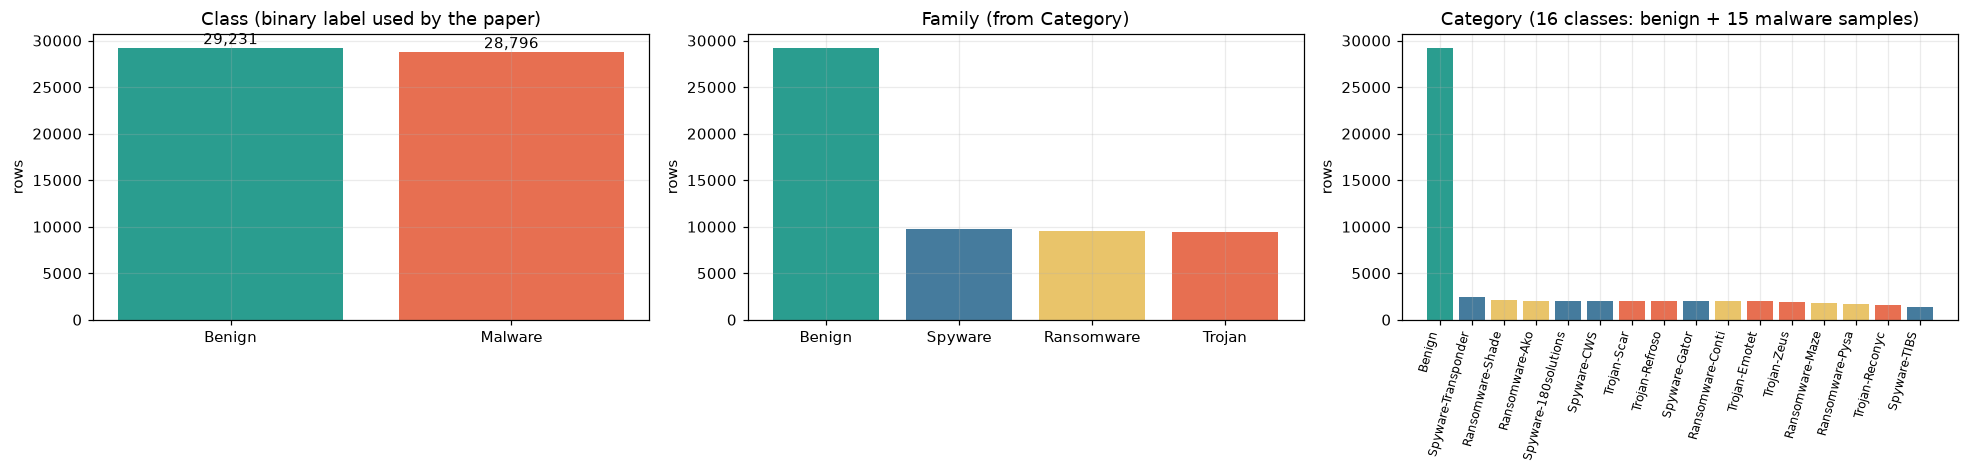

In [7]:
print("dataset shape (after cleaning):", df.shape, "| raw:", raw.shape)
print("feature names kept by the pipeline (%d):" % len(FEAT_KEPT)); print(FEAT_KEPT)
print("all %d numeric features:" % len(FEATURES), FEATURES[:8], "...")
print("original label values (Class):", raw["Class"].value_counts().to_dict())
display(df["Category"].value_counts().rename("rows").to_frame().T)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
cls = df["Class"].value_counts()
ax[0].bar(cls.index, cls.values, color=["#2a9d8f", "#e76f51"]); ax[0].set_title("Class (binary label used by the paper)")
for i, v in enumerate(cls.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
fam = df["family"].value_counts()
FAM_COL = {"Benign": "#2a9d8f", "Trojan": "#e76f51", "Spyware": "#457b9d", "Ransomware": "#e9c46a"}
ax[1].bar(fam.index, fam.values, color=[FAM_COL[f] for f in fam.index]); ax[1].set_title("Family (from Category)")
cat = df["Category"].value_counts()
ax[2].bar(range(len(cat)), cat.values, color=[FAM_COL[c.split("-")[0]] for c in cat.index]); ax[2].set_xticks(range(len(cat)))
ax[2].set_xticklabels(cat.index, rotation=75, ha="right", fontsize=8); ax[2].set_title("Category (16 classes: benign + 15 malware samples)")
for a in ax: a.set_ylabel("rows")
plt.tight_layout(); plt.show()

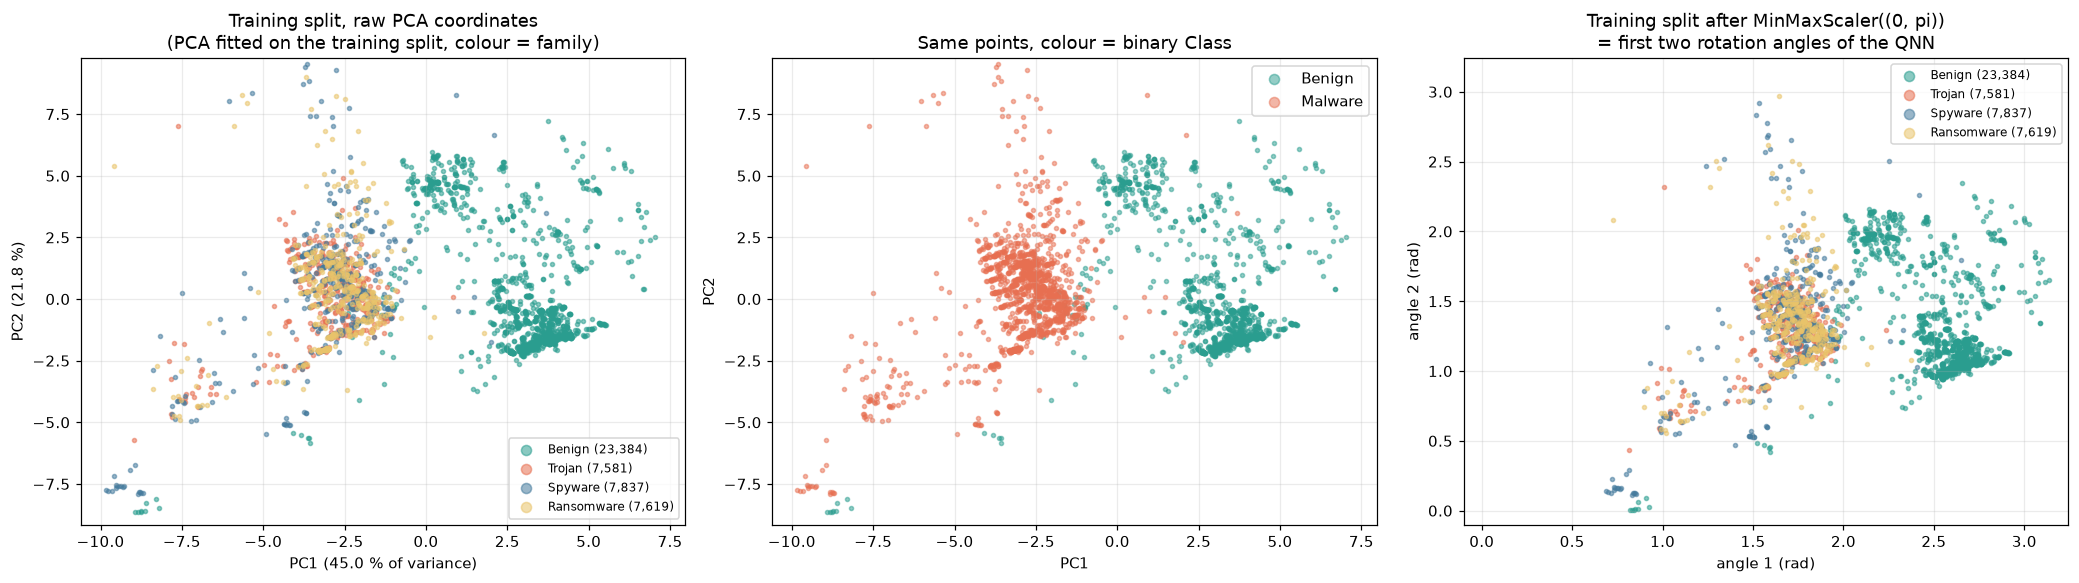

Benign rows form a compact cloud; Trojan, Spyware and Ransomware overlap it only partly in the first two components, the other 14 components carry the rest of the separation.


In [8]:
def scatter2(P, y, fam_, title, ax, lim=None, max_pts=3000, seed=SEED):
    r = np.random.default_rng(seed); sel = r.choice(len(P), min(max_pts, len(P)), replace=False)
    for f in ["Benign", "Trojan", "Spyware", "Ransomware"]:
        m = fam_[sel] == f
        ax.scatter(P[sel][m, 0], P[sel][m, 1], s=7, alpha=0.55, color=FAM_COL[f], label=f"{f} ({int((fam_ == f).sum()):,})")
    ax.set_title(title); ax.legend(markerscale=2.5, fontsize=8)

fam_tr = train_df["family"].to_numpy()
fig, ax = plt.subplots(1, 3, figsize=(19, 5.4))
scatter2(Ptr_all[:, :2], ytr_all, fam_tr, "Training split, raw PCA coordinates\n(PCA fitted on the training split, colour = family)", ax[0])
ax[0].set_xlabel(f"PC1 ({100*prep.pca.explained_variance_ratio_[0]:.1f} % of variance)"); ax[0].set_ylabel(f"PC2 ({100*prep.pca.explained_variance_ratio_[1]:.1f} %)")
lo, hi = np.quantile(Ptr_all[:, :2], 0.005, axis=0), np.quantile(Ptr_all[:, :2], 0.995, axis=0); pad = 0.1 * (hi - lo)
ax[0].set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax[0].set_ylim(lo[1] - pad[1], hi[1] + pad[1])
# binary view of the same coordinates
r = np.random.default_rng(SEED); sel = r.choice(len(Ptr_all), 3000, replace=False)
for yy, nm, col in ((0, "Benign", "#2a9d8f"), (1, "Malware", "#e76f51")):
    m = ytr_all[sel] == yy; ax[1].scatter(Ptr_all[sel][m, 0], Ptr_all[sel][m, 1], s=7, alpha=0.5, color=col, label=nm)
ax[1].set_xlim(ax[0].get_xlim()); ax[1].set_ylim(ax[0].get_ylim()); ax[1].set_title("Same points, colour = binary Class"); ax[1].legend(markerscale=2.5)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
scatter2(Atr_all[:, :2], ytr_all, fam_tr, "Training split after MinMaxScaler((0, pi))\n= first two rotation angles of the QNN", ax[2])
ax[2].set_xlabel("angle 1 (rad)"); ax[2].set_ylabel("angle 2 (rad)"); ax[2].set_xlim(-0.1, np.pi + 0.1); ax[2].set_ylim(-0.1, np.pi + 0.1)
plt.tight_layout(); plt.show()
print("Benign rows form a compact cloud; Trojan, Spyware and Ransomware overlap it only partly in the first two components,",
      "the other 14 components carry the rest of the separation.")

## 4. Classical baselines on identical inputs

Before any quantum model, the classical detectors the paper compares against are trained on **exactly the same data as the quantum models**: for every seed one class-balanced sample of `N_TRAIN` rows
is drawn from the training split, and every model is scored on the same fixed test subset. Two input sets are used: the **16 angles** (`MinMaxScaler((0, pi))` of the 16 PCA components, the very numbers the 16-qubit QNN receives)
and **all scaled features that survive the redundancy filter** (35). Random Forest, an RBF SVM (`C` chosen on a validation split of the training sample) and a small neural network (`MLP(64, 32)`, the paper's "classical neural network") are used.
Finally, a Random Forest on the *whole* training split shows what the classical ceiling is when data are not the bottleneck.

In [9]:
def metrics(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(Accuracy=100 * accuracy_score(y, p), Precision=100 * precision_score(y, p, zero_division=0),
                Recall=100 * recall_score(y, p), F1=100 * f1_score(y, p), FPR=100 * fp / max(fp + tn, 1), FNR=100 * fn / max(fn + tp, 1),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def draw(seed, n=None):
    # class-balanced training sample drawn from the training split
    n = n or N_TRAIN
    r = np.random.default_rng(seed)
    pos, neg = np.where(ytr_all == 1)[0], np.where(ytr_all == 0)[0]
    return np.sort(np.concatenate([r.choice(pos, n // 2, replace=False), r.choice(neg, n // 2, replace=False)]))

RES = {}          # (model, seed) -> dict(pred, prob, t_train, t_pred)
def store(name, seed, prob, t_train, t_pred):
    RES[(name, seed)] = dict(prob=np.asarray(prob), pred=(np.asarray(prob) >= 0.5).astype(int), t_train=t_train, t_pred=t_pred)

def fit_svc(X, y, seed):
    # C chosen on a validation split of the training sample only
    Xa, Xv, ya, yv = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
    best = max(SVM_C_GRID, key=lambda C: SVC(kernel="rbf", C=C, random_state=seed).fit(Xa, ya).score(Xv, yv))
    return SVC(kernel="rbf", C=best, probability=False, random_state=seed).fit(X, y), best

for seed in SEEDS:
    idx = draw(seed); ytr = ytr_all[idx]
    for tag, Xtr_, Xte_ in (("16 PCs", Atr_all[idx], Ate), ("all feats", Ztr_all[idx], Zte)):
        t = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=2).fit(Xtr_, ytr); tt = time.time() - t
        t = time.time(); pr = rf.predict_proba(Xte_)[:, 1]; store(f"RF ({tag})", seed, pr, tt, time.time() - t)
        t = time.time(); svc, C = fit_svc(Xtr_, ytr, seed); tt = time.time() - t
        t = time.time(); d = svc.decision_function(Xte_); store(f"SVC rbf ({tag})", seed, (d > 0).astype(float), tt, time.time() - t)
        t = time.time(); mlp = MLPClassifier((64, 32), max_iter=400, random_state=seed).fit(Xtr_, ytr); tt = time.time() - t
        t = time.time(); pr = mlp.predict_proba(Xte_)[:, 1]; store(f"MLP ({tag})", seed, pr, tt, time.time() - t)
t = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(Ztr_all, ytr_all); tt = time.time() - t
t = time.time(); pr = rf.predict_proba(Zte)[:, 1]; store("RF (all feats, full train split)", SEED, pr, tt, time.time() - t)
CLASSICAL = [k[0] for k in RES]
rows = {k: metrics(yte, v["pred"]) for k, v in RES.items() if k[1] == SEED}
display(pd.DataFrame({k[0]: {m: round(v[m], 2) for m in ("Accuracy", "Precision", "Recall", "F1", "FPR", "FNR")} for k, v in rows.items()}).T)
print(f"classical baselines done ({time.time()-T0:.0f} s since start)")

,Accuracy,Precision,Recall,F1,FPR,FNR
RF (16 PCs),98.93,98.79,99.06,98.93,1.19,0.94
SVC rbf (16 PCs),98.87,98.92,98.79,98.86,1.06,1.21
MLP (16 PCs),98.93,98.92,98.92,98.92,1.06,1.08
RF (all feats),99.20,98.80,99.60,99.20,1.19,0.40
SVC rbf (all feats),99.20,98.80,99.60,99.20,1.19,0.40
MLP (all feats),98.87,98.66,99.06,98.86,1.32,0.94
"RF (all feats, full train split)",100.00,100.00,100.00,100.00,0.00,0.00


classical baselines done (106 s since start)


## 5. A differentiable statevector simulator for the 16-qubit QNN

Training a 16-qubit circuit with 192 weights through PennyLane's `default.qubit` takes seconds per sample on a laptop CPU, which is too slow for a classroom run. The circuit has a very regular
structure, so the notebook contains a small **PyTorch statevector simulator**: the four single-qubit gates of a layer (`RX(x)`, `RZ`, `RY`, `RX`) are multiplied into one 2x2 matrix per qubit, the circular CNOT ladder is one fixed permutation of the 65 536 amplitudes,
and `<Z_0>` is read from the probabilities. Gradients come from PyTorch autograd (exact, equal to the parameter-shift rule the paper mentions for GradCAM++).
Section 6 draws the PennyLane circuit that this simulator imitates and **asserts that both give the same expectation value to 1e-4** for random weights, so the drawn circuit is the executed circuit.
The same simulator also runs the 6-qubit amplitude-encoded variant (QNN-B).

In [10]:
import torch.nn.functional as F

def rx_mat(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2); z = torch.zeros_like(c)
    return torch.complex(torch.stack([torch.stack([c, z], -1), torch.stack([z, c], -1)], -2),
                         torch.stack([torch.stack([z, -s], -1), torch.stack([-s, z], -1)], -2))
def ry_mat(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    re = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
    return torch.complex(re, torch.zeros_like(re))
def rz_mat(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2); z = torch.zeros_like(c)
    return torch.complex(torch.stack([torch.stack([c, z], -1), torch.stack([z, c], -1)], -2),
                         torch.stack([torch.stack([-s, z], -1), torch.stack([z, s], -1)], -2))

def ring_permutation(n):
    # CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0) applied in this order; wire 0 is the most significant bit (PennyLane convention)
    pos = np.arange(2 ** n)
    for q in range(n):
        c, t = q, (q + 1) % n
        pos = pos ^ (((pos >> (n - 1 - c)) & 1) << (n - 1 - t))
    return torch.as_tensor(np.argsort(pos))        # new_state = old_state[perm]

class StatevectorQNN(torch.nn.Module):
    # mode "angle": every layer re-uploads RX(x_q) before RZ-RY-RX on each qubit (QNN-A, 16 qubits)
    # mode "amp"  : the input is a normalised amplitude vector, layers contain only RZ-RY-RX (QNN-B, 6 qubits)
    def __init__(self, n, layers, mode, seed):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.n, self.layers, self.mode = n, layers, mode
        self.w = torch.nn.Parameter(0.5 * torch.randn(layers, n, 3, generator=g))     # CHOICE: N(0, 0.5) initial rotation angles
        self.scale = torch.nn.Parameter(torch.tensor(3.0))                             # CHOICE: trainable classical read-out
        self.bias = torch.nn.Parameter(torch.tensor(0.0))
        self.register_buffer("perm", ring_permutation(n))
    def zexp(self, X, w=None):
        w = self.w if w is None else w
        B, n = X.shape[0], self.n
        if self.mode == "angle":
            state = torch.zeros(B, 2 ** n, dtype=torch.complex64); state[:, 0] = 1
        else:
            state = torch.complex(X, torch.zeros_like(X))
        for l in range(self.layers):
            U = rx_mat(w[l, :, 2]) @ ry_mat(w[l, :, 1]) @ rz_mat(w[l, :, 0])          # (n, 2, 2): RX(c) RY(b) RZ(a)
            U = U.unsqueeze(0).expand(B, n, 2, 2)
            if self.mode == "angle":
                U = U @ rx_mat(X)                                                       # data (re-)uploading RX(x) first
            for k in range(n // 2):                                                     # two qubits at a time: one 4x4 gate (half the memory passes)
                P = torch.einsum("bij,bkl->bikjl", U[:, 2 * k], U[:, 2 * k + 1]).reshape(B, 4, 4)
                state = torch.matmul(P[:, None], state.reshape(B, 2 ** (2 * k), 4, 2 ** (n - 2 * k - 2))).reshape(B, -1)
            if n % 2:                                                                   # leftover single qubit (odd n)
                q = n - 1
                state = torch.einsum("bij,bljr->blir", U[:, q], state.reshape(B, 2 ** q, 2, 1)).reshape(B, -1)
            state = state[:, self.perm]
        p = state.real ** 2 + state.imag ** 2
        p0 = p.reshape(B, 2, -1).sum(-1)
        return p0[:, 0] - p0[:, 1]                                                      # <Z_0>
    def forward(self, X):
        return self.scale * (-self.zexp(X)) + self.bias                                 # logit of "malware" (<Z0> = -1 -> malware)

def to_amp(Z, n=N_AMP_QUBITS):
    # amplitude vector: pad with zeros to 2**n and normalise (|0...0> for an all-zero row)
    A = np.zeros((len(Z), 2 ** n), np.float32); A[:, :Z.shape[1]] = Z
    nr = np.linalg.norm(A, axis=1); z = nr == 0; A[z, 0] = 1; nr[z] = 1
    return (A / nr[:, None]).astype(np.float32)

@torch.no_grad()
def predict_prob(model, X, chunk=64):
    model.eval(); out = []
    for i in range(0, len(X), chunk):
        out.append(torch.sigmoid(model(torch.from_numpy(X[i:i + chunk]))).numpy())
    return np.concatenate(out)

def train_qnn(model, X, y, steps, batch, lr, max_seconds, seed, tag, log_every=10):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    r = np.random.default_rng(seed); order = []; hist = []; t0 = time.time()
    for step in range(1, steps + 1):
        model.train()
        if len(order) < batch: order = list(r.permutation(len(X)))
        ib = [order.pop() for _ in range(batch)]
        logits = model(torch.from_numpy(X[ib]))
        loss = F.binary_cross_entropy_with_logits(logits, torch.from_numpy(y[ib].astype(np.float32)))
        opt.zero_grad(); loss.backward(); opt.step()
        hist.append(float(loss))
        if step % log_every == 0 or step == 1:
            print(f"[{tag}] step {step:4d}/{steps}  loss(last {log_every}) {np.mean(hist[-log_every:]):.4f}  elapsed {time.time()-t0:6.1f} s", flush=True)
        if time.time() - t0 > max_seconds:
            print(f"[{tag}] wall-clock cap of {max_seconds} s reached after {step} of {steps} steps"); break
    return hist, step, time.time() - t0

# speed check of the simulator
_m = StatevectorQNN(N_QUBITS, N_LAYERS, "angle", SEED)
_t = time.time(); _l = _m(torch.rand(QNN_BATCH, N_QUBITS) * np.pi).sum(); _l.backward(); print(f"one forward+backward pass, batch {QNN_BATCH}, 16 qubits: {time.time()-_t:.2f} s")
del _m, _l

one forward+backward pass, batch 16, 16 qubits: 8.97 s


## 6. Quantum Circuit Architecture

Three gate-based quantum models are trained or evaluated, so three circuits are drawn. For each one the **PennyLane QNode** is drawn with `qml.draw_mpl`, its qubit count, depth and trainable-parameter count are printed
from `qml.specs`, and the QNode's output is compared with the simulator used for training (assertion). The paper only gives a schematic (Figure 1) and the sentences quoted in the table of choices, so every omitted detail is listed here:

| Detail the paper omits | Choice made |
|---|---|
| Where the data enter a 16-qubit circuit with 57 features | QNN-A: one `RX(x_q)` per qubit at the start of **every** layer (data re-uploading, "each layer containing data encoding gates") |
| Which 16 numbers | the 16 PCA components scaled to `[0, pi]` |
| Rotation order | Eq. 4 `Rz Ry Rx` read as: `RZ`, then `RY`, then `RX` (applied in this order to each qubit) |
| Entangler | `CNOT(q, q+1 mod 16)` for `q = 0..15` in this order after every layer ("circular topology") |
| Measurement | `<Z>` on qubit 0, mapped to a logit by a trainable scale and bias |
| Amplitude encoding (Eq. 3) | QNN-B: 6 qubits, `AmplitudeEmbedding` of the padded, normalised scaled features (35 here), then four `RZ-RY-RX` + CNOT-ring layers |
| QSVM circuit | 8 qubits, `IQPEmbedding(n_repeats=2)`, kernel = squared overlap of the two prepared states (Eq. 5) |

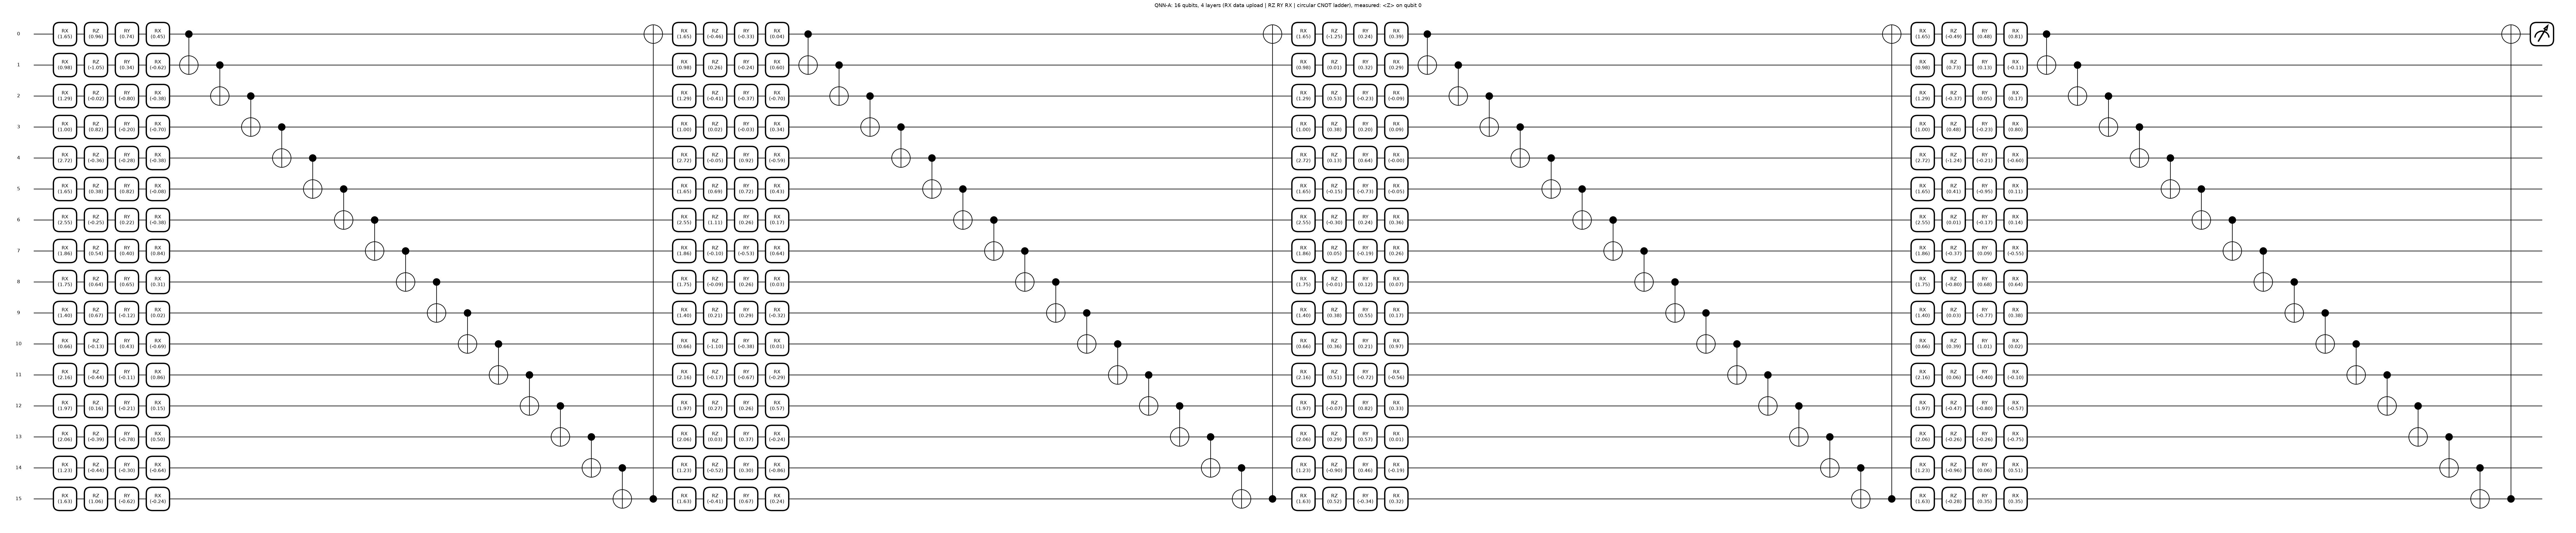

QNN-A: qubits 16, depth 80, gates 320, trainable circuit weights 192 (+2 classical read-out parameters)


PennyLane <Z0>: [ 0.007889 -0.006261  0.004485] | simulator <Z0>: [ 0.007889 -0.006261  0.004485] | max abs diff 6.81e-08  (8 s)


In [11]:
n, L = N_QUBITS, N_LAYERS
dev16 = qml.device("default.qubit", wires=n)
@qml.qnode(dev16)
def qnn_a(x, w):
    for l in range(L):
        for q in range(n): qml.RX(x[..., q], wires=q)                      # data (re-)uploading (x may carry a batch axis)
        for q in range(n):
            qml.RZ(w[l, q, 0], wires=q); qml.RY(w[l, q, 1], wires=q); qml.RX(w[l, q, 2], wires=q)   # Eq. 4: parameterised rotations
        for q in range(n): qml.CNOT(wires=[q, (q + 1) % n])                # circular entangling ladder
    return qml.expval(qml.PauliZ(0))

m_a = StatevectorQNN(n, L, "angle", SEED)
w0 = m_a.w.detach().numpy().astype(float); x0 = Ate[0].astype(float)
fig, ax = qml.draw_mpl(qnn_a, decimals=2, fontsize=11)(x0, w0)
fig.suptitle("QNN-A: 16 qubits, 4 layers (RX data upload | RZ RY RX | circular CNOT ladder), measured: <Z> on qubit 0", y=1.0); plt.show()
sp = qml.specs(qnn_a, level="device")(x0, w0)["resources"]
print(f"QNN-A: qubits {len(qnn_a.device.wires)}, depth {sp.depth}, gates {sp.num_gates}, trainable circuit weights {w0.size} (+2 classical read-out parameters)")
# equivalence: PennyLane QNode (batched call) vs the training simulator, random weights, 3 test samples
t = time.time(); ref = np.asarray(qnn_a(Ate[:3].astype(float), w0)); sim = m_a.zexp(torch.from_numpy(Ate[:3])).detach().numpy()
print("PennyLane <Z0>:", np.round(ref, 6), "| simulator <Z0>:", np.round(sim, 6), f"| max abs diff {np.abs(ref - sim).max():.2e}  ({time.time()-t:.0f} s)")
assert np.abs(ref - sim).max() < 1e-4, "simulator and PennyLane circuit disagree"

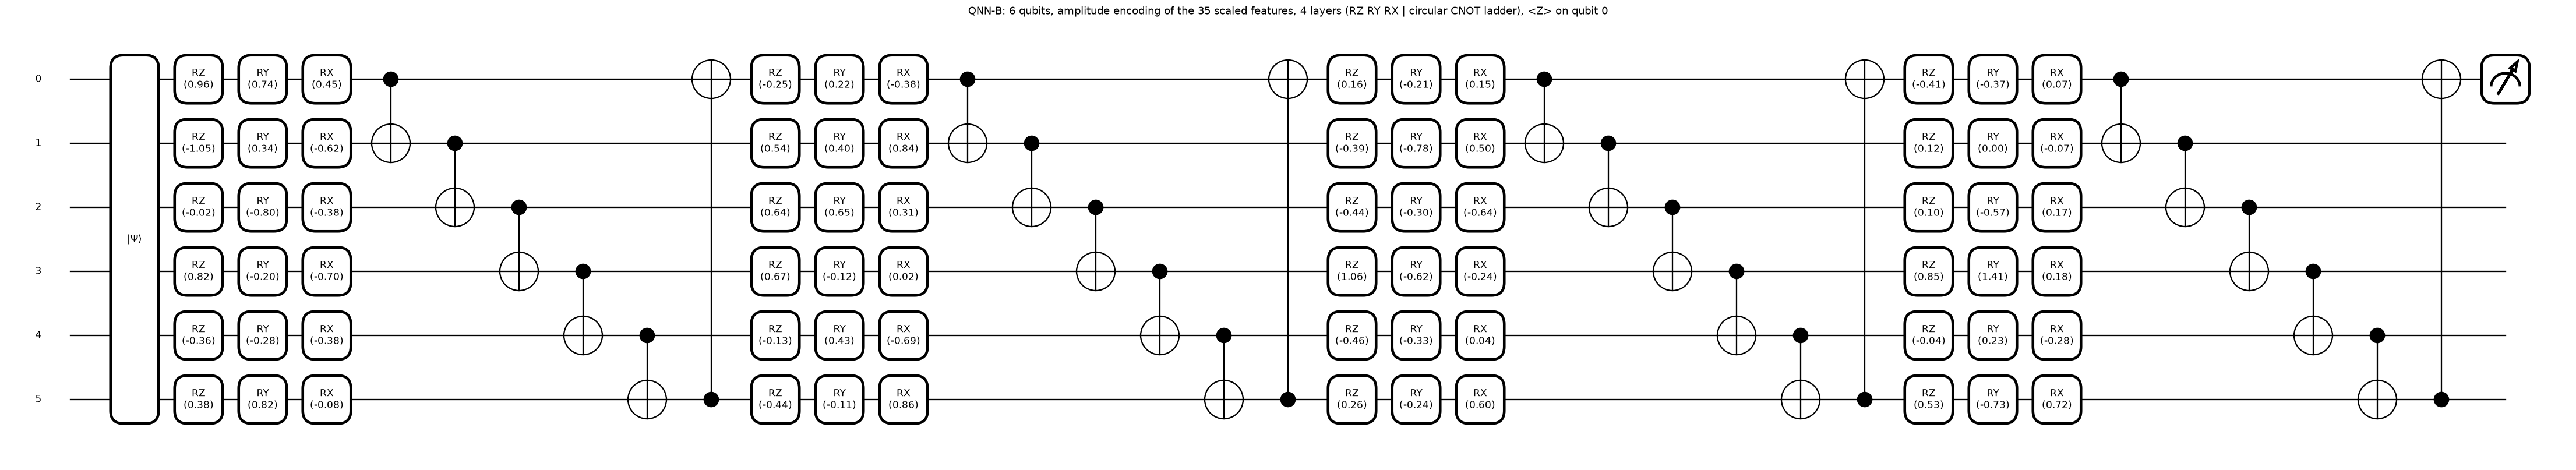

QNN-B: qubits 6, depth 37, gates 97, trainable circuit weights 72 (+2 classical read-out parameters)
PennyLane <Z0>: [-1.73338e-01  3.11000e-04 -2.19828e-01 -3.25135e-01 -3.33377e-01] | simulator <Z0>: [-1.73338e-01  3.11000e-04 -2.19828e-01 -3.25135e-01 -3.33377e-01] | max abs diff 1.42e-07


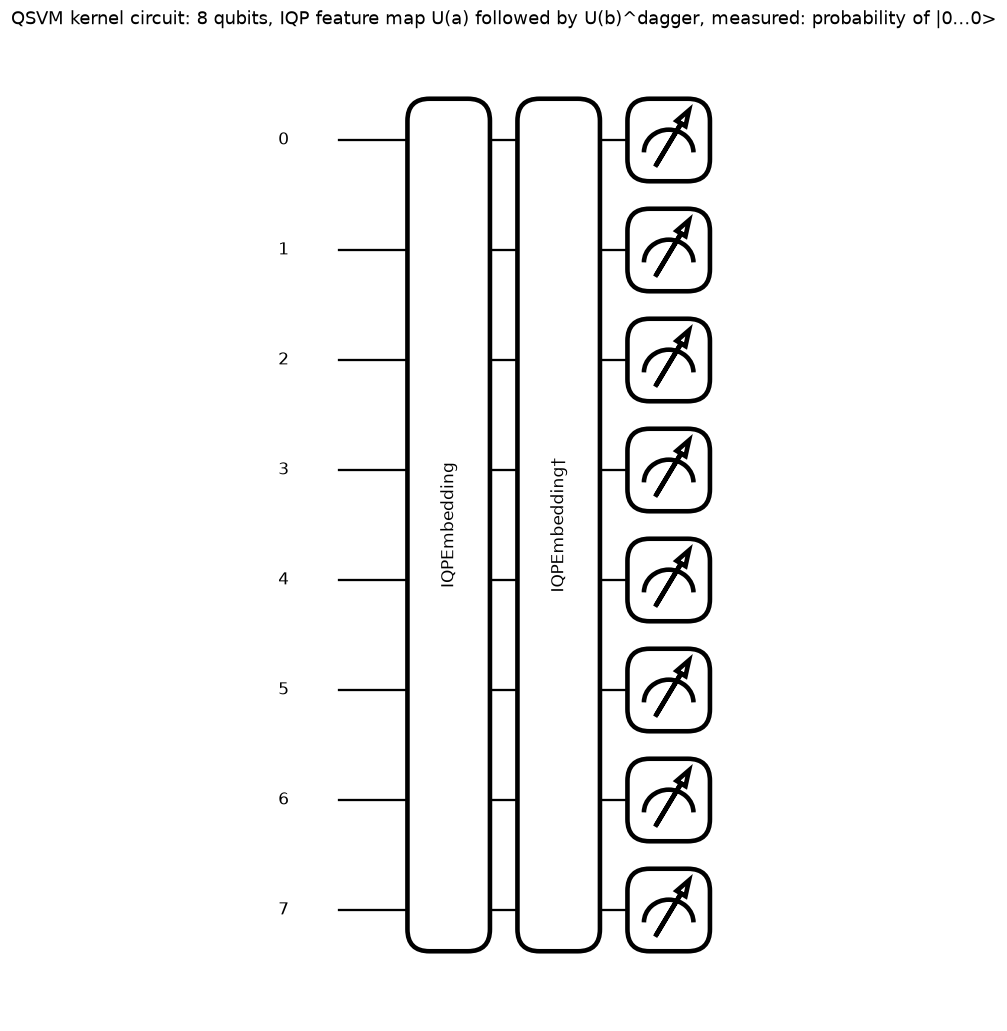

QSVM kernel circuit: qubits 8, depth 50, gates 176, trainable parameters 0 (the angle scale and the SVM C are hyper-parameters)
kernel from the executed circuit: 0.004773463232254286 | from the two statevectors: 0.0047734632322542925


In [12]:
na = N_AMP_QUBITS
dev6 = qml.device("default.qubit", wires=na)
@qml.qnode(dev6)
def qnn_b(x, w):
    qml.AmplitudeEmbedding(x, wires=range(na), pad_with=0.0, normalize=True)       # Eq. 3: amplitude encoding of the scaled features
    for l in range(L):
        for q in range(na):
            qml.RZ(w[l, q, 0], wires=q); qml.RY(w[l, q, 1], wires=q); qml.RX(w[l, q, 2], wires=q)
        for q in range(na): qml.CNOT(wires=[q, (q + 1) % na])
    return qml.expval(qml.PauliZ(0))

m_b = StatevectorQNN(na, L, "amp", SEED)
wb = m_b.w.detach().numpy().astype(float)
fig, ax = qml.draw_mpl(qnn_b, decimals=2, fontsize=11)(Zte[0].astype(float), wb)
fig.suptitle("QNN-B: 6 qubits, amplitude encoding of the 35 scaled features, 4 layers (RZ RY RX | circular CNOT ladder), <Z> on qubit 0", y=1.02); plt.show()
sp = qml.specs(qnn_b, level="device")(Zte[0].astype(float), wb)["resources"]
print(f"QNN-B: qubits {len(qnn_b.device.wires)}, depth {sp.depth}, gates {sp.num_gates}, trainable circuit weights {wb.size} (+2 classical read-out parameters)")
ref = np.asarray(qnn_b(Zte[:5].astype(float), wb)); sim = m_b.zexp(torch.from_numpy(to_amp(Zte[:5]))).detach().numpy()
print("PennyLane <Z0>:", np.round(ref, 6), "| simulator <Z0>:", np.round(sim, 6), f"| max abs diff {np.abs(ref - sim).max():.2e}")
assert np.abs(ref - sim).max() < 1e-4, "simulator and PennyLane circuit disagree"

nq8 = N_QUBITS_QSVM
dev8 = qml.device("default.qubit", wires=nq8)
@qml.qnode(dev8)
def kernel_circuit(a, b):
    qml.IQPEmbedding(a, wires=range(nq8), n_repeats=2)                              # U(a)
    qml.adjoint(qml.IQPEmbedding(b, wires=range(nq8), n_repeats=2))                 # U(b)^dagger
    return qml.probs(wires=range(nq8))                                              # P(|0...0>) = kernel value (Eq. 5)
@qml.qnode(dev8)
def feature_state(x):
    qml.IQPEmbedding(x, wires=range(nq8), n_repeats=2)
    return qml.state()

a8, b8 = Ate[0, :nq8].astype(float), Ate[1, :nq8].astype(float)
fig, ax = qml.draw_mpl(kernel_circuit, decimals=2, fontsize=11)(a8, b8)
fig.suptitle("QSVM kernel circuit: 8 qubits, IQP feature map U(a) followed by U(b)^dagger, measured: probability of |0...0>", y=1.02); plt.show()
sp = qml.specs(kernel_circuit, level="device")(a8, b8)["resources"]
print(f"QSVM kernel circuit: qubits {len(kernel_circuit.device.wires)}, depth {sp.depth}, gates {sp.num_gates}, trainable parameters 0 (the angle scale and the SVM C are hyper-parameters)")
Sa, Sb = np.asarray(feature_state(a8)), np.asarray(feature_state(b8))
print("kernel from the executed circuit:", float(kernel_circuit(a8, b8)[0]), "| from the two statevectors:", float(np.abs(np.vdot(Sa, Sb)) ** 2))
assert abs(float(kernel_circuit(a8, b8)[0]) - float(np.abs(np.vdot(Sa, Sb)) ** 2)) < 1e-8

## 7. Training the 16-qubit QNN (QNN-A)

Binary cross-entropy on the logit `scale * (-<Z_0>) + bias`, Adam with learning rate 0.05, mini-batches of 16 balanced training rows. The budget in `FAST_MODE` is deliberately small (the wall-clock cap in the configuration cell
ends training if the CPU is busy); the `FAST_MODE = False` budget is 300 steps per seed with a cap of 1000 s. On the shared CPU on which the committed outputs were produced, the cap ended every full-run training after about 150 to 160 of the 300 steps (see the printed message); on a faster machine the full 300 steps are performed. The training time and the number of steps that were really performed are printed.

[QNN-A seed 42] step    1/300  loss(last 10) 0.6987  elapsed    5.3 s


[QNN-A seed 42] step   10/300  loss(last 10) 0.6758  elapsed   84.0 s


[QNN-A seed 42] step   20/300  loss(last 10) 0.5669  elapsed  162.9 s


[QNN-A seed 42] step   30/300  loss(last 10) 0.3618  elapsed  228.3 s


[QNN-A seed 42] step   40/300  loss(last 10) 0.1717  elapsed  284.1 s


...

[QNN-A seed 44] step  130/300  loss(last 10) 0.0561  elapsed  785.1 s


[QNN-A seed 44] step  140/300  loss(last 10) 0.0305  elapsed  851.5 s


[QNN-A seed 44] step  150/300  loss(last 10) 0.0387  elapsed 1016.9 s


[QNN-A seed 44] wall-clock cap of 1000 s reached after 150 of 300 steps


seed 44: 150 steps in 1017 s, prediction of 1500 rows in 312.9 s -> test accuracy 98.27 %


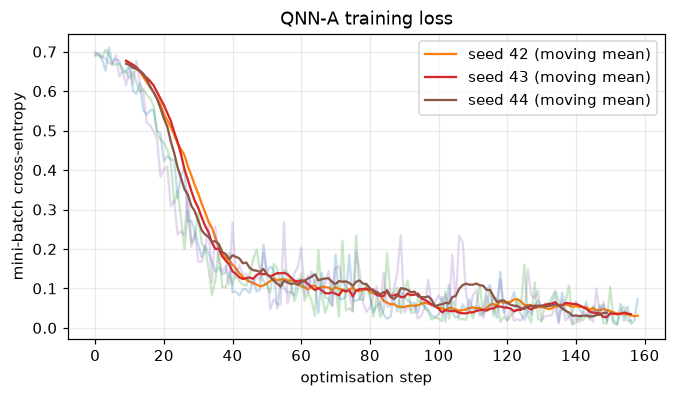

trained weights, PennyLane vs simulator max abs diff: 4.125337014215802e-07


In [13]:
QNN_INFO = {}
for seed in SEEDS:
    idx = draw(seed); ytr = ytr_all[idx]
    torch.manual_seed(seed)
    model = StatevectorQNN(N_QUBITS, N_LAYERS, "angle", seed)
    hist, done, secs = train_qnn(model, Atr_all[idx], ytr, QNN_STEPS, QNN_BATCH, QNN_LR, QNN_MAX_SECONDS, seed, f"QNN-A seed {seed}")
    t = time.time(); pr = predict_prob(model, Ate); tp = time.time() - t
    store("QNN-A (16 qubits, angle re-uploading)", seed, pr, secs, tp)
    QNN_INFO[seed] = dict(hist=hist, steps=done, model=model)
    print(f"seed {seed}: {done} steps in {secs:.0f} s, prediction of {len(Ate)} rows in {tp:.1f} s -> test accuracy {metrics(yte, RES[('QNN-A (16 qubits, angle re-uploading)', seed)]['pred'])['Accuracy']:.2f} %")
fig, ax = plt.subplots(figsize=(7, 3.6))
for seed in SEEDS:
    h = np.array(QNN_INFO[seed]["hist"]); k = max(1, len(h) // 15)
    ax.plot(np.arange(len(h)), h, alpha=0.25); ax.plot(np.arange(k - 1, len(h)), np.convolve(h, np.ones(k) / k, "valid"), label=f"seed {seed} (moving mean)")
ax.set_xlabel("optimisation step"); ax.set_ylabel("mini-batch cross-entropy"); ax.set_title("QNN-A training loss"); ax.legend(); plt.show()
# the drawn PennyLane circuit is the trained circuit: re-check with the trained weights of the first seed
m_t = QNN_INFO[SEEDS[0]]["model"]
ref = np.asarray(qnn_a(Ate[:2].astype(float), m_t.w.detach().numpy().astype(float))); sim = m_t.zexp(torch.from_numpy(Ate[:2])).detach().numpy()
print("trained weights, PennyLane vs simulator max abs diff:", float(np.abs(ref - sim).max())); assert np.abs(ref - sim).max() < 1e-4

## 8. The amplitude-encoded variant (QNN-B)

Equation 3 of the paper encodes the feature vector in the *amplitudes* of the state, which needs only `ceil(log2(35)) = 6` qubits. The same four layers are applied to those 6 qubits.
This variant is cheap, so it gets more optimisation steps. It is the literal reading of the paper's data-encoding equation.

In [14]:
QNNB_INFO = {}
for seed in SEEDS:
    idx = draw(seed); ytr = ytr_all[idx]
    torch.manual_seed(seed)
    model = StatevectorQNN(N_AMP_QUBITS, N_LAYERS, "amp", seed)
    hist, done, secs = train_qnn(model, to_amp(Ztr_all[idx]), ytr, AMP_STEPS, QNN_BATCH, QNN_LR, 600, seed, f"QNN-B seed {seed}", log_every=25)
    t = time.time(); pr = predict_prob(model, to_amp(Zte)); tp = time.time() - t
    store("QNN-B (6 qubits, amplitude encoding)", seed, pr, secs, tp)
    QNNB_INFO[seed] = dict(hist=hist, steps=done)
    print(f"seed {seed}: {done} steps in {secs:.0f} s -> test accuracy {metrics(yte, RES[('QNN-B (6 qubits, amplitude encoding)', seed)]['pred'])['Accuracy']:.2f} %")

[QNN-B seed 42] step    1/400  loss(last 25) 0.6625  elapsed    0.2 s


[QNN-B seed 42] step   25/400  loss(last 25) 0.5337  elapsed    3.0 s


[QNN-B seed 42] step   50/400  loss(last 25) 0.4138  elapsed    5.8 s


[QNN-B seed 42] step   75/400  loss(last 25) 0.3688  elapsed    8.7 s


[QNN-B seed 42] step  100/400  loss(last 25) 0.3135  elapsed   12.5 s


...

[QNN-B seed 44] step  325/400  loss(last 25) 0.2375  elapsed   51.3 s


[QNN-B seed 44] step  350/400  loss(last 25) 0.1723  elapsed   57.3 s


[QNN-B seed 44] step  375/400  loss(last 25) 0.2246  elapsed   61.3 s


[QNN-B seed 44] step  400/400  loss(last 25) 0.2091  elapsed   65.1 s


seed 44: 400 steps in 65 s -> test accuracy 91.20 %


## 9. The quantum-kernel SVM (QSVM)

The kernel is the squared overlap of two states prepared by the IQP feature map on 8 qubits (the first 8 angles, multiplied by an angle scale that acts as the kernel bandwidth). The Gram matrices are computed
exactly from the statevectors of the circuit in section 6 (`feature_state`), checked against the kernel circuit itself, and handed to `SVC(kernel="precomputed")`. The angle scale and `C` are chosen on a validation
split of the training sample only.

In [15]:
def states(A, scale, chunk=100):
    out = [np.asarray(feature_state(scale * A[i:i + chunk, :nq8].astype(float))) for i in range(0, len(A), chunk)]
    return np.concatenate(out).astype(np.complex128)
def gram(S1, S2): return np.abs(S1 @ S2.conj().T) ** 2

QSVM_NAME = "QSVM (8 qubits, IQP kernel)"
QSVM_INFO = {}
for seed in SEEDS:
    idx = draw(seed); ytr = ytr_all[idx]; Atr = Atr_all[idx]
    t = time.time()
    itr, iva = train_test_split(np.arange(len(idx)), test_size=0.3, stratify=ytr, random_state=seed)
    best, tab = None, []
    for sc in QSVM_SCALE_GRID:
        S = states(Atr, sc); Ktr = gram(S[itr], S[itr]); Kva = gram(S[iva], S[itr])
        for C in SVM_C_GRID:
            acc = SVC(kernel="precomputed", C=C).fit(Ktr, ytr[itr]).score(Kva, ytr[iva]); tab.append((sc, C, acc))
            if best is None or acc > best[2]: best = (sc, C, acc)
    sc, C, _ = best
    S = states(Atr, sc); K = gram(S, S)
    clf = SVC(kernel="precomputed", C=C).fit(K, ytr); tt = time.time() - t
    t = time.time(); Ste = states(Ate, sc); Kte = gram(Ste, S); d = clf.decision_function(Kte); tp = time.time() - t
    store(QSVM_NAME, seed, (d > 0).astype(float), tt, tp)
    QSVM_INFO[seed] = dict(scale=sc, C=C, table=tab, K=K, ytr=ytr, Kte=Kte)
    print(f"seed {seed}: best angle scale {sc}, C {C} (validation accuracy {best[2]:.3f}); train {tt:.0f} s, predict {tp:.0f} s -> test accuracy {metrics(yte, RES[(QSVM_NAME, seed)]['pred'])['Accuracy']:.2f} %")
# kernel sanity checks on the executed kernel circuit: symmetric, unit diagonal, equal to the circuit value
sc = QSVM_INFO[SEEDS[0]]["scale"]; Atr0 = Atr_all[draw(SEEDS[0])]
K0 = QSVM_INFO[SEEDS[0]]["K"]
chk = [(0, 1), (2, 5), (3, 7)]
circ_vals = [float(kernel_circuit(sc * Atr0[i, :nq8].astype(float), sc * Atr0[j, :nq8].astype(float))[0]) for i, j in chk]
print("kernel entries from the circuit:", np.round(circ_vals, 6), "| from statevectors:", np.round([K0[i, j] for i, j in chk], 6))
assert np.allclose(circ_vals, [K0[i, j] for i, j in chk], atol=1e-8) and np.allclose(np.diag(K0), 1) and np.allclose(K0, K0.T)
print("smallest eigenvalue of the training Gram matrix:", float(np.linalg.eigvalsh(K0).min()), "(>= 0 up to rounding: positive semi-definite)")

seed 42: best angle scale 0.25, C 1.0 (validation accuracy 1.000); train 66 s, predict 20 s -> test accuracy 98.73 %


seed 43: best angle scale 0.25, C 10.0 (validation accuracy 0.997); train 65 s, predict 18 s -> test accuracy 99.27 %


seed 44: best angle scale 0.25, C 10.0 (validation accuracy 0.997); train 64 s, predict 24 s -> test accuracy 99.13 %


kernel entries from the circuit: [0.995153 0.979753 0.827149] | from statevectors: [0.995153 0.979753 0.827149]


smallest eigenvalue of the training Gram matrix: -2.9978955584944786e-14 (>= 0 up to rounding: positive semi-definite)


## 10. Metrics: tables and confusion matrices

Malware is the positive class. Every model is scored on the same fixed test subset; the table gives mean +- standard deviation over the seeds in `SEEDS` (one seed in `FAST_MODE`, so the deviation is 0 there).

test subset: 1500 rows; training sample per seed: 1000 (balanced); seeds [42, 43, 44]; metrics in %


,Accuracy,Precision,Recall,F1,FPR,FNR,train s,predict s
"QNN-A (16 qubits, angle re-uploading)",98.33 +- 0.25,97.32 +- 0.40,99.37 +- 0.23,98.34 +- 0.25,2.69 +- 0.41,0.63 +- 0.23,1008.3,207.46
"QNN-B (6 qubits, amplitude encoding)",92.96 +- 1.24,93.89 +- 2.02,91.89 +- 3.82,92.80 +- 1.42,6.00 +- 2.32,8.11 +- 3.82,64.1,2.17
"QSVM (8 qubits, IQP kernel)",99.04 +- 0.23,98.50 +- 0.44,99.60 +- 0.00,99.04 +- 0.22,1.50 +- 0.45,0.40 +- 0.00,64.9,20.37
RF (16 PCs),99.27 +- 0.24,99.37 +- 0.44,99.15 +- 0.13,99.26 +- 0.24,0.62 +- 0.44,0.85 +- 0.13,4.3,0.63
SVC rbf (16 PCs),99.00 +- 0.09,98.97 +- 0.06,99.01 +- 0.17,98.99 +- 0.10,1.01 +- 0.06,0.99 +- 0.17,0.2,0.07
MLP (16 PCs),99.11 +- 0.17,99.20 +- 0.48,99.01 +- 0.23,99.10 +- 0.17,0.79 +- 0.47,0.99 +- 0.23,6.4,0.01
RF (all feats),99.42 +- 0.17,99.24 +- 0.38,99.60 +- 0.11,99.42 +- 0.17,0.75 +- 0.38,0.40 +- 0.11,3.1,0.81
SVC rbf (all feats),99.40 +- 0.24,99.29 +- 0.52,99.51 +- 0.06,99.40 +- 0.24,0.71 +- 0.51,0.49 +- 0.06,0.2,0.07
MLP (all feats),99.33 +- 0.33,99.46 +- 0.58,99.19 +- 0.11,99.33 +- 0.33,0.53 +- 0.57,0.81 +- 0.11,1.8,0.00
"RF (all feats, full train split)",100.00 +- 0.00,100.00 +- 0.00,100.00 +- 0.00,100.00 +- 0.00,0.00 +- 0.00,0.00 +- 0.00,32.9,0.55


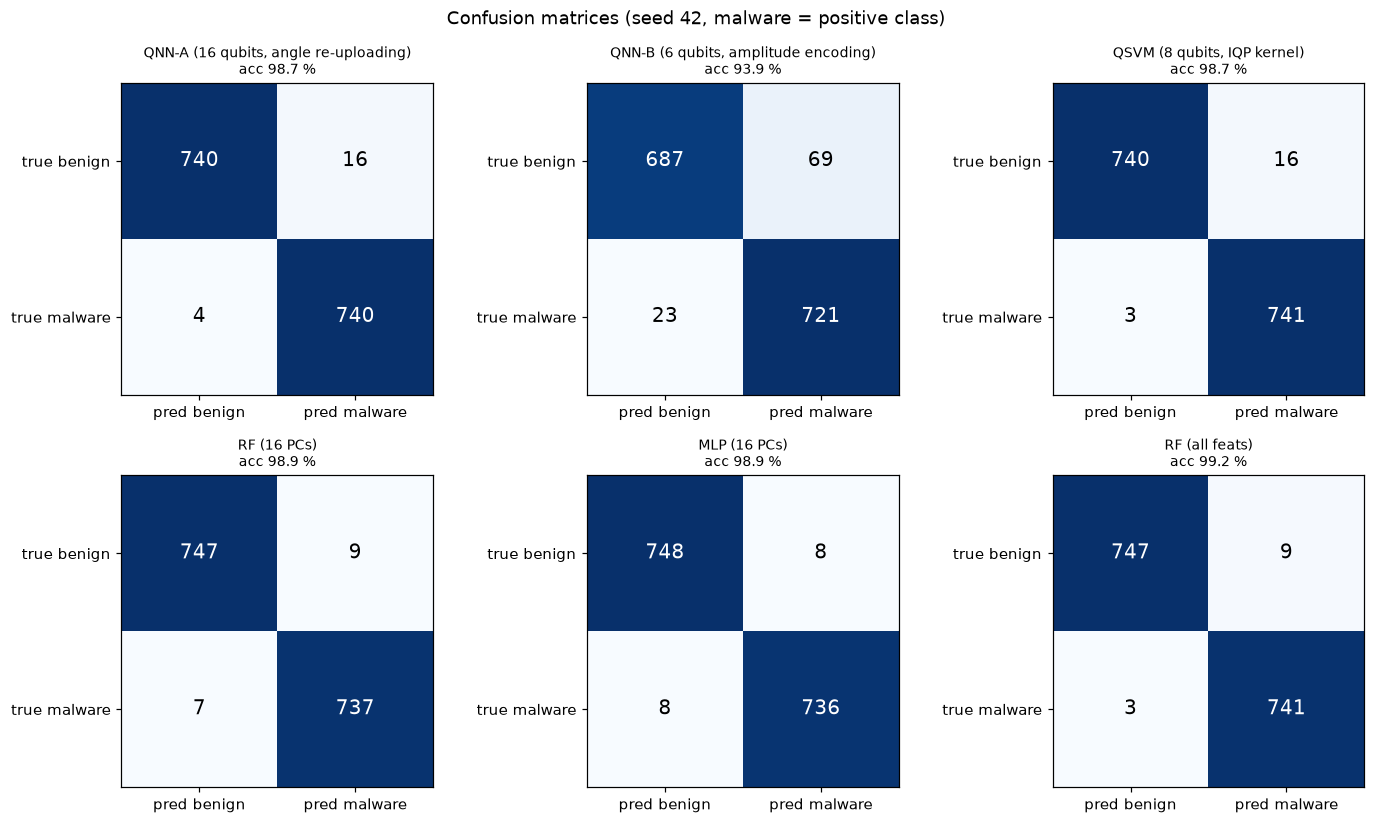

In [16]:
MODEL_ORDER = ["QNN-A (16 qubits, angle re-uploading)", "QNN-B (6 qubits, amplitude encoding)", QSVM_NAME,
               "RF (16 PCs)", "SVC rbf (16 PCs)", "MLP (16 PCs)", "RF (all feats)", "SVC rbf (all feats)", "MLP (all feats)", "RF (all feats, full train split)"]
def per_model(name):
    ms = [metrics(yte, RES[(name, s)]["pred"]) for s in SEEDS if (name, s) in RES]
    return pd.DataFrame(ms)
SUMMARY = {}
for name in MODEL_ORDER:
    d = per_model(name)
    SUMMARY[name] = {m: (d[m].mean(), d[m].std(ddof=0)) for m in ("Accuracy", "Precision", "Recall", "F1", "FPR", "FNR")}
    SUMMARY[name]["train s"] = np.mean([RES[(name, s)]["t_train"] for s in SEEDS if (name, s) in RES])
    SUMMARY[name]["predict s"] = np.mean([RES[(name, s)]["t_pred"] for s in SEEDS if (name, s) in RES])
tab = pd.DataFrame({n: {**{m: f"{SUMMARY[n][m][0]:.2f} +- {SUMMARY[n][m][1]:.2f}" for m in ("Accuracy", "Precision", "Recall", "F1", "FPR", "FNR")},
                        "train s": f"{SUMMARY[n]['train s']:.1f}", "predict s": f"{SUMMARY[n]['predict s']:.2f}"} for n in MODEL_ORDER}).T
print(f"test subset: {len(yte)} rows; training sample per seed: {N_TRAIN} (balanced); seeds {SEEDS}; metrics in %")
display(tab)

s0 = SEEDS[0]
show = ["QNN-A (16 qubits, angle re-uploading)", "QNN-B (6 qubits, amplitude encoding)", QSVM_NAME, "RF (16 PCs)", "MLP (16 PCs)", "RF (all feats)"]
fig, ax = plt.subplots(2, 3, figsize=(13, 7.6))
for a, name in zip(ax.ravel(), show):
    cm = confusion_matrix(yte, RES[(name, s0)]["pred"], labels=[0, 1])
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["pred benign", "pred malware"]); a.set_yticklabels(["true benign", "true malware"])
    a.set_title(f"{name}\nacc {metrics(yte, RES[(name, s0)]['pred'])['Accuracy']:.1f} %", fontsize=9)
plt.suptitle(f"Confusion matrices (seed {s0}, malware = positive class)"); plt.tight_layout(); plt.show()

## 11. Re-drawing the paper's figures

Figure 2 of the paper compares quantum and classical methods on accuracy, precision, recall and F1. The first panel below redraws it with the paper's numbers (hatched) next to the numbers obtained here.
Figure 4 reports accuracy per malware family; the paper's families (virus, worm, trojan, backdoor, rootkit) do not exist in CIC-MalMem-2022, whose families are Trojan, Spyware and Ransomware, so the second panel
shows the detection rate per **dataset** family instead.

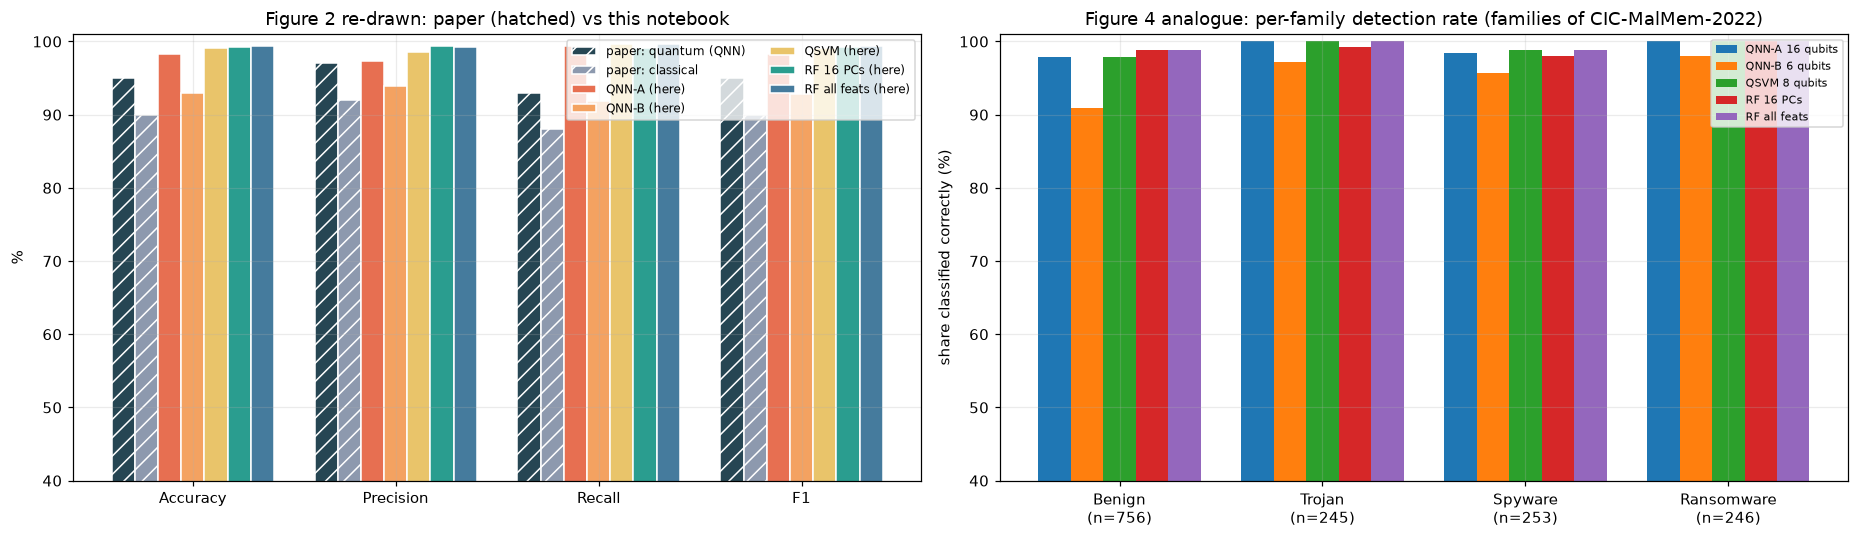

In [17]:
METRICS4 = ["Accuracy", "Precision", "Recall", "F1"]
paper_q = dict(Accuracy=95, Precision=97, Recall=93, F1=95); paper_c = dict(Accuracy=90, Precision=92, Recall=88, F1=90)
bars = [("paper: quantum (QNN)", [paper_q[m] for m in METRICS4], "#264653", "//"), ("paper: classical", [paper_c[m] for m in METRICS4], "#8d99ae", "//"),
        ("QNN-A (here)", [SUMMARY[show[0]][m][0] for m in METRICS4], "#e76f51", None), ("QNN-B (here)", [SUMMARY[show[1]][m][0] for m in METRICS4], "#f4a261", None),
        ("QSVM (here)", [SUMMARY[show[2]][m][0] for m in METRICS4], "#e9c46a", None), ("RF 16 PCs (here)", [SUMMARY[show[3]][m][0] for m in METRICS4], "#2a9d8f", None),
        ("RF all feats (here)", [SUMMARY[show[5]][m][0] for m in METRICS4], "#457b9d", None)]
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
w = 0.8 / len(bars)
for k, (lab, vals, col, hatch) in enumerate(bars):
    ax[0].bar(np.arange(4) + k * w, vals, w, label=lab, color=col, hatch=hatch, edgecolor="white")
ax[0].set_xticks(np.arange(4) + 0.4 - w / 2); ax[0].set_xticklabels(METRICS4); ax[0].set_ylim(40, 101); ax[0].set_ylabel("%"); ax[0].legend(fontsize=8, ncol=2)
ax[0].set_title("Figure 2 re-drawn: paper (hatched) vs this notebook")
fam_te = te["family"].to_numpy(); fams = ["Benign", "Trojan", "Spyware", "Ransomware"]
fam_models = [show[0], show[1], show[2], show[3], show[5]]
for k, name in enumerate(fam_models):
    pred = RES[(name, s0)]["pred"]; true = yte
    vals = [100 * np.mean(pred[fam_te == f] == true[fam_te == f]) for f in fams]
    ax[1].bar(np.arange(4) + k * 0.16, vals, 0.16, label=name.split(",")[0].replace(" (", " ").replace(")", ""))
ax[1].set_xticks(np.arange(4) + 0.32); ax[1].set_xticklabels([f"{f}\n(n={int((fam_te == f).sum())})" for f in fams]); ax[1].set_ylim(40, 101)
ax[1].set_ylabel("share classified correctly (%)"); ax[1].legend(fontsize=7); ax[1].set_title("Figure 4 analogue: per-family detection rate (families of CIC-MalMem-2022)")
plt.tight_layout(); plt.show()

## 12. Extra checks of the paper's other claims

* **Throughput and latency** (paper: 1000 samples/s, 15 ms per sample, versus 100 samples/s and 150 ms for classical methods): measured here on the CPU simulator, which says nothing about hardware but shows what a classical simulation of the circuit costs.
* **Bootstrap confidence interval** (paper: 1000 resamples, QNN accuracy 0.942 to 0.958): percentile interval of the test-set accuracy, plus the paired difference to the Random Forest on the same 16 inputs.
* **Explainability** (paper: GradCAM++ and ScoreCAM): a ScoreCAM-style, gradient-free measure. Each of the 16 input angles is replaced in turn by its training mean (a "masked input"); the importance is the average drop of the probability the QNN gives to the true class.
  The paper's human-agreement figures (93 % correlation, kappa 0.89, 89 % trust) need expert annotations that are not available and cannot be checked.

In [18]:
# --- throughput and latency (prediction only, CPU, batch of 64 for the QNN simulator) ---
q_name = show[0]
n_te = len(Ate)
THR = {}
for name in (q_name, show[1], QSVM_NAME, "RF (16 PCs)", "MLP (16 PCs)"):
    tp = np.mean([RES[(name, s)]["t_pred"] for s in SEEDS if (name, s) in RES])
    THR[name] = (n_te / tp, 1000 * tp / n_te)
display(pd.DataFrame(THR, index=["samples / s", "ms / sample"]).T.round(2))

# --- bootstrap ---
rb = np.random.default_rng(SEED)
boot_idx = rb.integers(0, n_te, size=(N_BOOT, n_te))
def boot_acc(pred): return 100 * (pred[boot_idx] == yte[boot_idx]).mean(axis=1)
BOOT = {n: boot_acc(RES[(n, s0)]["pred"]) for n in (q_name, show[1], QSVM_NAME, "RF (16 PCs)", "RF (all feats)")}
for n, b in BOOT.items(): print(f"{n:45s} accuracy {100*np.mean(RES[(n, s0)]['pred']==yte):6.2f} %   95 % bootstrap interval [{np.percentile(b, 2.5):6.2f}, {np.percentile(b, 97.5):6.2f}]")
diff = BOOT[q_name] - BOOT["RF (16 PCs)"]
print(f"paired difference QNN-A minus RF(16 PCs): mean {diff.mean():+.2f} points, 95 % interval [{np.percentile(diff, 2.5):+.2f}, {np.percentile(diff, 97.5):+.2f}]  (paper: +5 points)")

,samples / s,ms / sample
"QNN-A (16 qubits, angle re-uploading)",7.23,138.31
"QNN-B (6 qubits, amplitude encoding)",690.03,1.45
"QSVM (8 qubits, IQP kernel)",73.63,13.58
RF (16 PCs),2373.05,0.42
MLP (16 PCs),242697.84,0.00


QNN-A (16 qubits, angle re-uploading)         accuracy  98.67 %   95 % bootstrap interval [ 98.07,  99.20]
QNN-B (6 qubits, amplitude encoding)          accuracy  93.87 %   95 % bootstrap interval [ 92.60,  95.07]
QSVM (8 qubits, IQP kernel)                   accuracy  98.73 %   95 % bootstrap interval [ 98.13,  99.27]
RF (16 PCs)                                   accuracy  98.93 %   95 % bootstrap interval [ 98.40,  99.40]
RF (all feats)                                accuracy  99.20 %   95 % bootstrap interval [ 98.73,  99.60]
paired difference QNN-A minus RF(16 PCs): mean -0.26 points, 95 % interval [-0.67, +0.13]  (paper: +5 points)


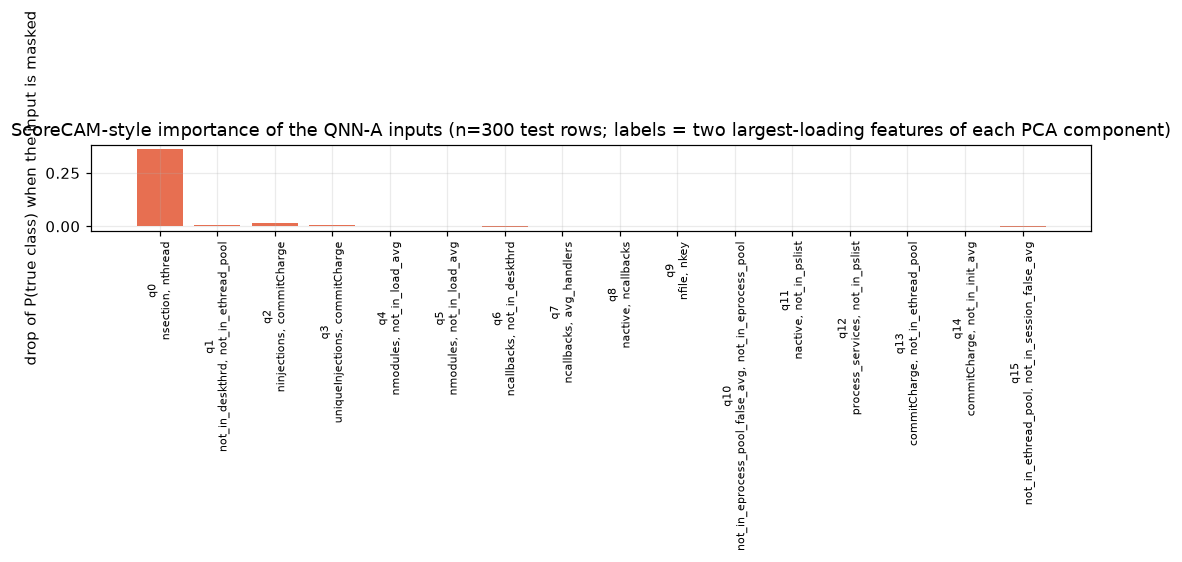

most influential inputs: [('q0', 0.362, 'nsection, nthread'), ('q2', 0.017, 'ninjections, commitCharge'), ('q3', 0.008, 'uniqueInjections, commitCharge'), ('q1', 0.007, 'not_in_deskthrd, not_in_ethread_pool')]


In [19]:
# --- ScoreCAM-style masking importance of the 16 inputs of QNN-A ---
rs = np.random.default_rng(SEED)
sel = rs.choice(len(Ate), min(N_IMPORTANCE, len(Ate)), replace=False)
model = QNN_INFO[s0]["model"]; Xs, ys = Ate[sel], yte[sel]
def true_prob(X): p = predict_prob(model, X); return np.where(ys == 1, p, 1 - p)
base = true_prob(Xs).mean(); mean_angle = Atr_all.mean(axis=0)
imp = []
for q in range(N_QUBITS):
    Xm = Xs.copy(); Xm[:, q] = mean_angle[q]
    imp.append(base - true_prob(Xm).mean())
imp = np.array(imp)
comp = np.abs(prep.pca.components_)
top = [", ".join(FEAT_KEPT[j].split(".")[-1] for j in np.argsort(-comp[q])[:2]) for q in range(N_QUBITS)]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(range(N_QUBITS), imp, color="#e76f51"); ax.set_xticks(range(N_QUBITS)); ax.set_xticklabels([f"q{q}\n{top[q]}" for q in range(N_QUBITS)], rotation=90, fontsize=7)
ax.set_ylabel("drop of P(true class) when the input is masked"); ax.set_title(f"ScoreCAM-style importance of the QNN-A inputs (n={len(sel)} test rows; labels = two largest-loading features of each PCA component)")
plt.tight_layout(); plt.show()
print("most influential inputs:", [(f"q{q}", round(float(imp[q]), 3), top[q]) for q in np.argsort(-imp)[:4]])

## 13. Paper versus this notebook

Rule (from the project brief): a claim is **reproduced** when the notebook value is within 2 percentage points (0.02 for F1 as a fraction) of the paper's; otherwise it is **not reached** (below) or **exceeded** (above) with the gap;
claims that need hardware, human experts or data that are not public are **cannot be checked**.

In [20]:
def verdict(paper, ours, tol=PAPER_TOL, higher_better=True):
    gap = ours - paper
    if abs(gap) <= tol: return f"reproduced (gap {gap:+.1f})"
    better = gap > 0 if higher_better else gap < 0
    return f"{'exceeded' if better else 'not reached'} (gap {gap:+.1f})"
S = SUMMARY; qa, qb, qs = show[0], show[1], show[2]
rf16, rf52, mlp16, mlp52 = "RF (16 PCs)", "RF (all feats)", "MLP (16 PCs)", "MLP (all feats)"
rows = [
 ("QNN accuracy (abstract, IV-A)", "95 %", f"QNN-A {S[qa]['Accuracy'][0]:.1f} %, QNN-B {S[qb]['Accuracy'][0]:.1f} %", verdict(95, max(S[qa]['Accuracy'][0], S[qb]['Accuracy'][0]))),
 ("QNN precision (IV-A)", "97 %", f"QNN-A {S[qa]['Precision'][0]:.1f} %", verdict(97, S[qa]['Precision'][0])),
 ("QNN recall (IV-A)", "93 %", f"QNN-A {S[qa]['Recall'][0]:.1f} %", verdict(93, S[qa]['Recall'][0])),
 ("QNN F1 (IV-A)", "95 %", f"QNN-A {S[qa]['F1'][0]:.1f} %", verdict(95, S[qa]['F1'][0])),
 ("QNN false-positive rate (IV-A)", "2 %", f"QNN-A {S[qa]['FPR'][0]:.1f} %", verdict(2, S[qa]['FPR'][0], higher_better=False)),
 ("QNN false-negative rate (IV-A; text implies 7 % from recall 93 %)", "5 %", f"QNN-A {S[qa]['FNR'][0]:.1f} %", verdict(5, S[qa]['FNR'][0], higher_better=False)),
 ("QSVM accuracy (abstract)", "94 %", f"{S[qs]['Accuracy'][0]:.1f} %", verdict(94, S[qs]['Accuracy'][0])),
 ("Classical Random Forest accuracy (IV-A)", "90 %", f"16 PCs {S[rf16]['Accuracy'][0]:.1f} %, all features {S[rf52]['Accuracy'][0]:.1f} %, full train split {S['RF (all feats, full train split)']['Accuracy'][0]:.1f} %", verdict(90, S[rf52]['Accuracy'][0])),
 ("Classical neural network accuracy (IV-A)", "90 %", f"MLP 16 PCs {S[mlp16]['Accuracy'][0]:.1f} %, all features {S[mlp52]['Accuracy'][0]:.1f} %", verdict(90, S[mlp52]['Accuracy'][0])),
 ("Classical precision / recall / F1 / FPR / FNR (IV-A)", "92 / 88 / 90 / 6 / 12 %", f"RF all feats {S[rf52]['Precision'][0]:.1f} / {S[rf52]['Recall'][0]:.1f} / {S[rf52]['F1'][0]:.1f} / {S[rf52]['FPR'][0]:.1f} / {S[rf52]['FNR'][0]:.1f} %", verdict(90, S[rf52]['F1'][0])),
 ("Quantum advantage: QNN minus Random Forest on the same 16 inputs", "+5 points", f"{S[qa]['Accuracy'][0]-S[rf16]['Accuracy'][0]:+.1f} points (QNN-A), {S[qb]['Accuracy'][0]-S[rf16]['Accuracy'][0]:+.1f} (QNN-B), {S[qs]['Accuracy'][0]-S[rf16]['Accuracy'][0]:+.1f} (QSVM)",
  "reproduced" if S[qa]['Accuracy'][0] - S[rf16]['Accuracy'][0] >= 3 else f"not reached (gap {S[qa]['Accuracy'][0]-S[rf16]['Accuracy'][0]-5:+.1f})"),
 ("QNN accuracy confidence interval (IV-E)", "0.942 to 0.958", f"[{np.percentile(BOOT[q_name], 2.5)/100:.3f}, {np.percentile(BOOT[q_name], 97.5)/100:.3f}] (QNN-A, {N_BOOT} bootstrap resamples)",
  "reproduced" if (np.percentile(BOOT[q_name], 2.5) <= 95.8 and np.percentile(BOOT[q_name], 97.5) >= 94.2) else "not reached (interval does not overlap)"),
 ("Throughput (IV-B, IV-F)", "1000 samples/s", f"{THR[q_name][0]:.0f} samples/s (QNN-A simulator), RF {THR['RF (16 PCs)'][0]:.0f}", "reproduced" if THR[q_name][0] >= 1000 else f"not reached ({THR[q_name][0]:.0f} vs 1000)"),
 ("Latency (IV-B, IV-F)", "15 ms / sample", f"{THR[q_name][1]:.1f} ms (QNN-A simulator), RF {THR['RF (16 PCs)'][1]:.2f} ms", "reproduced" if THR[q_name][1] <= 17 else f"not reached ({THR[q_name][1]:.1f} ms)"),
 ("Per-family accuracy: virus 98, worm 97, trojan 96, backdoor 95, rootkit 94 % (Fig. 4)", "5 families", "dataset has Trojan, Spyware, Ransomware (see section 11)", "cannot be checked (families differ; only Trojan overlaps)"),
 ("Time complexity O(log n) vs O(n^2) (IV-B, Fig. 3)", "log n", "state-vector simulation costs O(2^qubits) per sample", "cannot be checked (needs fault-tolerant hardware / QRAM)"),
 ("Explainability: 93 % correlation with experts, 89 % trust, kappa 0.89 (IV-D)", "human study", "ScoreCAM-style masking only (section 12)", "cannot be checked (no expert annotations)"),
 ("Second 'Intrusion' dataset: 150 samples, 56 Volatility features", "used", "dataset not identified or public", "cannot be checked"),
 ("Bootstrap p < 0.001, Cohen d 0.94 to 1.31 (IV-E)", "statistics", f"paired QNN-A minus RF(16 PCs) difference {diff.mean():+.2f} points", "cannot be checked (test unspecified; effect is opposite or absent here)" if diff.mean() < 2 else "reproduced in sign"),
]
CMP = pd.DataFrame(rows, columns=["Claim (paper section)", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 140, "display.width", 250)
display(CMP.style.hide(axis="index").set_properties(**{"text-align": "left"}))
print(CMP["Verdict"].str.split(" ").str[0].value_counts().to_dict())
print(f"total notebook time {time.time()-T0:.0f} s | FAST_MODE={FAST_MODE}")

Claim (paper section),Paper,This notebook,Verdict
"QNN accuracy (abstract, IV-A)",95 %,"QNN-A 98.3 %, QNN-B 93.0 %",exceeded (gap +3.3)
QNN precision (IV-A),97 %,QNN-A 97.3 %,reproduced (gap +0.3)
QNN recall (IV-A),93 %,QNN-A 99.4 %,exceeded (gap +6.4)
QNN F1 (IV-A),95 %,QNN-A 98.3 %,exceeded (gap +3.3)
QNN false-positive rate (IV-A),2 %,QNN-A 2.7 %,reproduced (gap +0.7)
QNN false-negative rate (IV-A; text implies 7 % from recall 93 %),5 %,QNN-A 0.6 %,exceeded (gap -4.4)
QSVM accuracy (abstract),94 %,99.0 %,exceeded (gap +5.0)
Classical Random Forest accuracy (IV-A),90 %,"16 PCs 99.3 %, all features 99.4 %, full train split 100.0 %",exceeded (gap +9.4)
Classical neural network accuracy (IV-A),90 %,"MLP 16 PCs 99.1 %, all features 99.3 %",exceeded (gap +9.3)
Classical precision / recall / F1 / FPR / FNR (IV-A),92 / 88 / 90 / 6 / 12 %,RF all feats 99.2 / 99.6 / 99.4 / 0.7 / 0.4 %,exceeded (gap +9.4)


{'exceeded': 8, 'cannot': 5, 'not': 4, 'reproduced': 2}
total notebook time 4874 s | FAST_MODE=False


## 14. Reading the paper critically

* **The headline number is reachable, the comparison is not.** A 16-qubit QNN of the kind described reaches the paper's 95 % accuracy on CIC-MalMem-2022 and, with the longer training of the full run, exceeds it (about 98 %, section 10). But the paper's *classical* baselines of 90 % are far below what the same
  inputs give with a Random Forest, an RBF SVM or a small MLP (about 98 to 99 % here, and 100 % for a Random Forest trained on the whole training split). The "5-point quantum advantage" is therefore an artefact of weak or untuned classical baselines,
  not a property of the quantum model: on identical inputs the quantum models are at best level with the classical ones (QSVM) and about one point or less below (QNN-A, see the bootstrap interval of the paired difference in section 12; QNN-B with amplitude encoding is clearly worse).
* **Unspecified experimental protocol.** Split, training size, optimiser, learning rate, loss, PCA dimension, QSVM width and feature map, classical hyper-parameters and the number of runs are not given, so the 95 / 94 / 90 numbers cannot be traced to a protocol.
  The paper's stated precision (97 %), recall (93 %) and false-negative rate (5 %) are mutually inconsistent (a recall of 93 % means a false-negative rate of 7 %); the quoted accuracy interval (0.942 to 0.958) is too narrow for any test set of realistic size unless the test set is large and the model very stable.
* **Inconsistent circuit description.** "16 qubits" and "amplitude encoding of 57 features" cannot both hold (57 amplitudes need 6 qubits, 16 qubits could hold 65 536). Both readings are implemented here (QNN-A and QNN-B); neither can be matched to the paper's Figure 1 uniquely.
* **What the QNN really uses.** The masking importance of section 12 shows that the 16-qubit model relies almost entirely on the first PCA component (the other 15 inputs hardly change its output). CIC-MalMem-2022 is close to linearly separable along that component, so the data do not need
  16 entangled qubits; the dataset is too easy to discriminate between methods, and random splits of memory snapshots taken from the same malware samples are likely to put near-duplicates on both sides of the split (Exercise 4).
* **Complexity and speed claims are not supported by the experiments.** `O(log n)` training time and 1000 samples/s at 15 ms latency are asserted without a measurement; a classical statevector simulation of 16 qubits costs `O(2^16)` per gate and is the slowest model here
  (section 12). A real quantum advantage of this type would require QRAM and fault-tolerant hardware.
* **The explainability and human-trust numbers (93 %, 89 %, kappa 0.89), the "Intrusion" dataset of 150 samples, the families virus/worm/rootkit/backdoor and the statistical tests (bootstrap p < 0.001, Cohen's d 0.94 to 1.31) are not accompanied by data or code** and cannot be reproduced.
  Section 11 shows the families that the public dataset really contains (Trojan, Spyware, Ransomware).
* **Take-away.** The paper is a plausible but under-specified and over-claimed demonstration: the quantum numbers are reproducible, the quantum *advantage* is not.

## 15. Exercises

1. **Width and depth.** Set `N_QUBITS = 8` (and keep four layers), then `N_LAYERS = 1, 2, 8`. How do accuracy, training time per step and the loss curve change? Is the 16-qubit width needed for this dataset?
2. **Training size.** Increase `N_TRAIN` to 100, 300, 1000, 3000 for the quantum and classical models. Plot accuracy against `N_TRAIN`. At what size does the Random Forest saturate, and does the QNN ever catch up?
3. **Encoding.** Replace the `RX` data re-uploading of QNN-A by a single encoding layer at the start (upload once) and compare. Then replace the amplitude encoding of QNN-B by angle encoding of the first six PCA components. Which encoding choice matters most?
4. **Honest evaluation.** The capture file name (`Filename`) groups rows that come from the same memory dump. Use `GroupShuffleSplit` on it instead of a stratified random split. Do the classical and quantum scores change? Which of the paper's numbers would survive such a split?
5. **Kernel bandwidth.** Print the validation table stored in `QSVM_INFO[SEED]["table"]` for the angle scales 0.25 to 2. Add 4 and 8 and plot the Gram matrix of 100 training rows for a too-small and a too-large scale (what does a near-identity Gram matrix mean for generalisation?).